<div style="border-top:8px solid #E2178F; border-bottom:3px solid #E2178F; border-radius:10px; padding:23px 25px; background:#FFF8FC; font-family:Arial,Helvetica,sans-serif; margin-bottom:18px;">
  <div style="display:flex; align-items:center; gap:22px;">
    <div style="flex:1; min-width:0;">
      <div style="color:#E2178F; font-size:12px; font-weight:800; letter-spacing:2px;">RAJASTHAN ROYALS &nbsp; · &nbsp; SUPERR SELECTOR SEASON 2</div>
      <div style="color:#14234A; font-size:32px; font-weight:800; line-height:1.16; margin:12px 0;">IDENTIFYING THE MOST RELIABLE<br>PLAYERS UNDER PRESSURE</div>
    </div>
    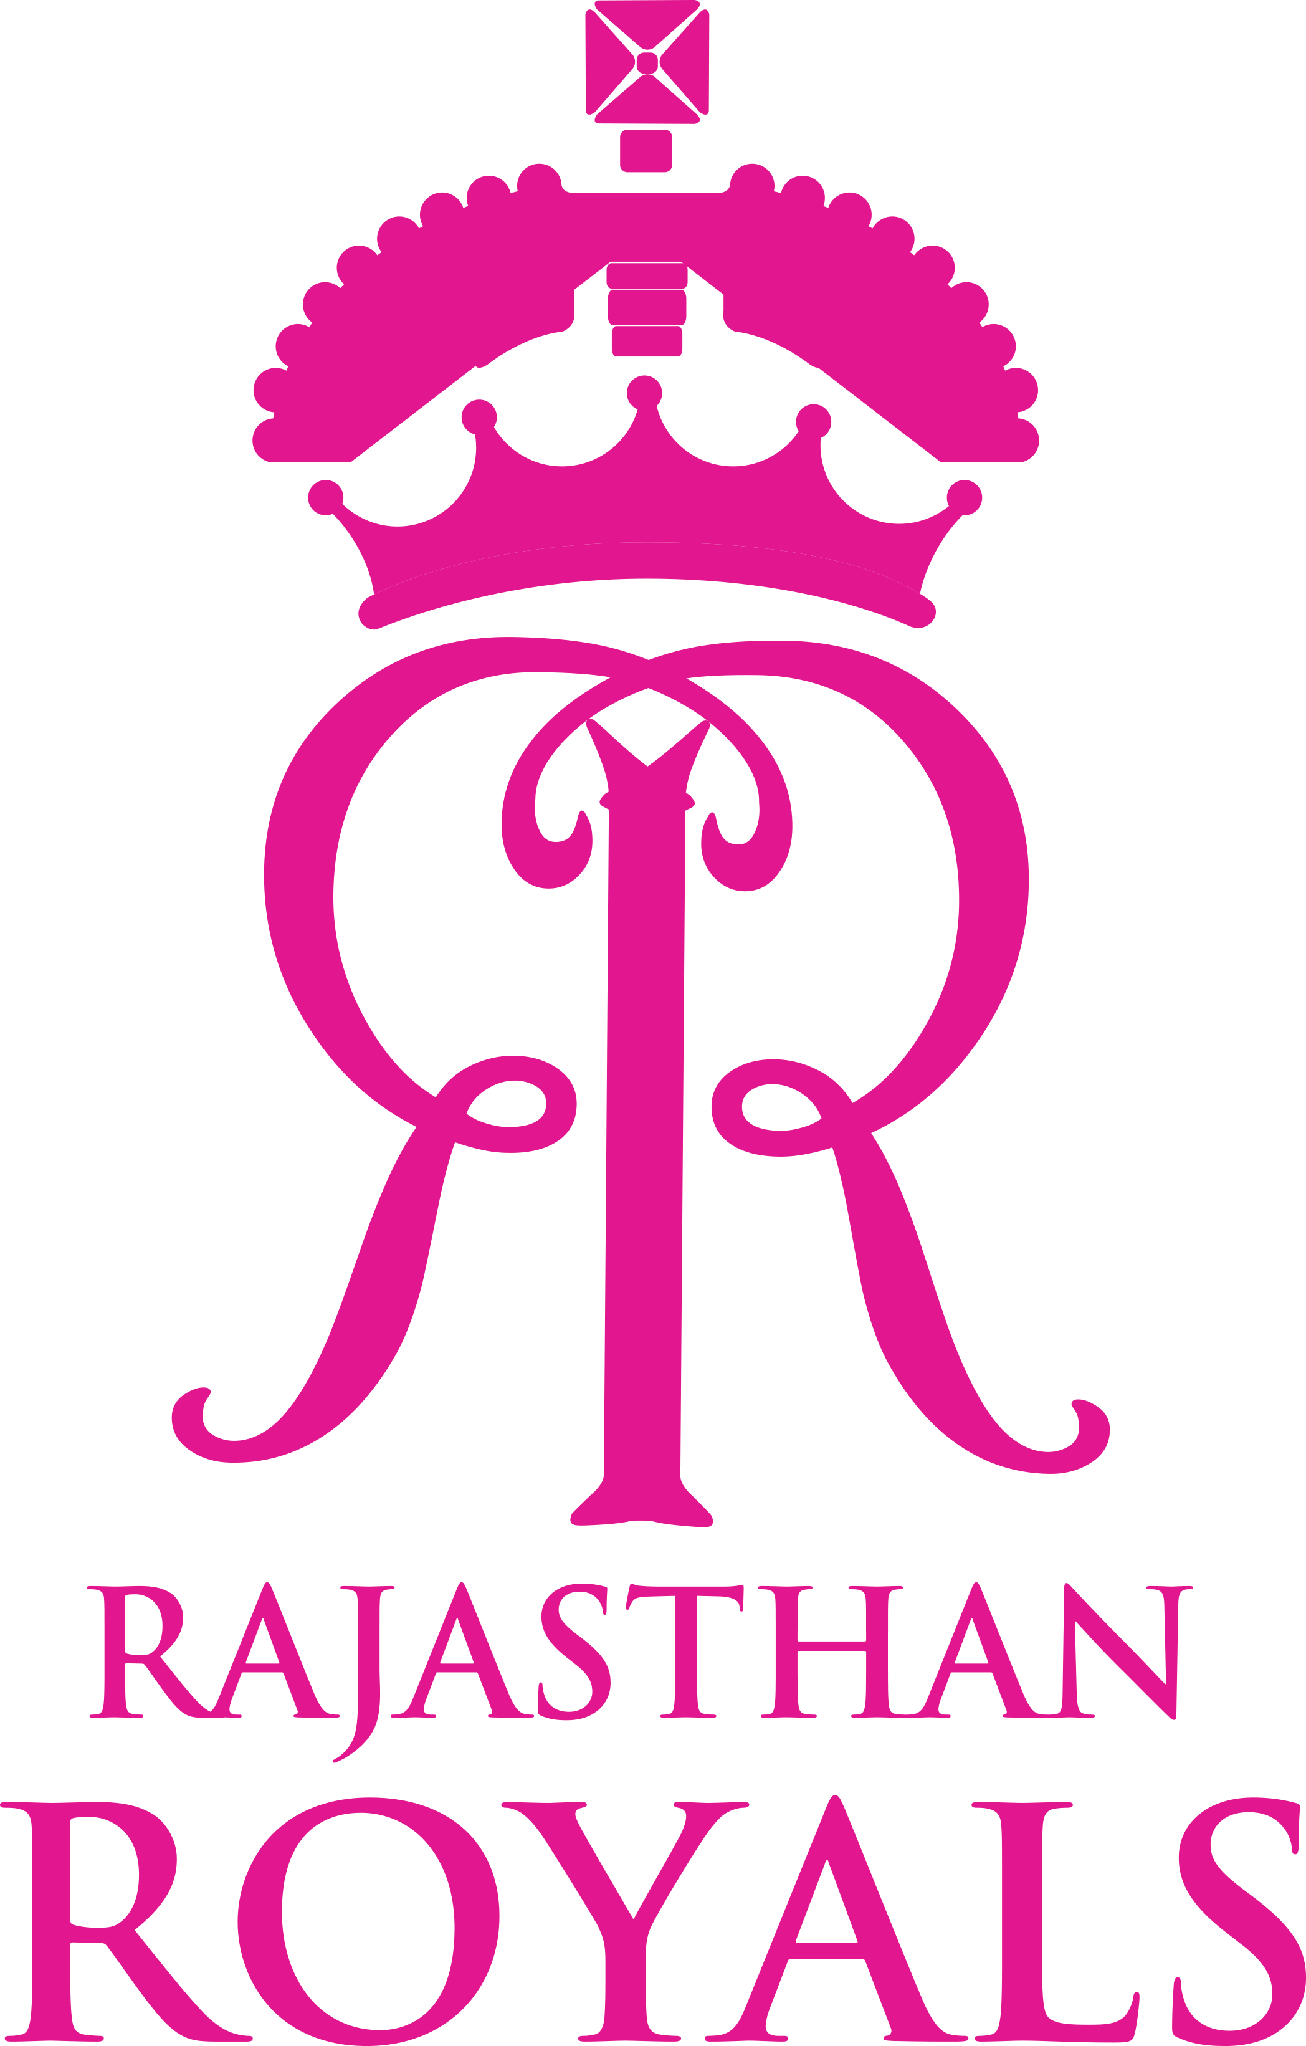
  </div>
  <div style="border-top:1px solid #E6B7D0; margin-top:20px; padding-top:12px; font-size:12px; color:#14234A; letter-spacing:.5px; font-weight:700;">32 BATTING PRESSURE SIGNALS &nbsp; · &nbsp; 34 BOWLING PRESSURE SIGNALS &nbsp; · &nbsp; TWO FINAL TOP-10 LISTS</div>
</div>

**Study population:** Supplied IPL and T20 International ball-by-ball observations from 2022–2026. The analysis exports exactly two ordered lists: 10 batters and 10 bowlers.

**Research objective:** Compare player responses in observable high-pressure match contexts with their ordinary performance while accounting for opponent strength, match exposure, and uncertainty. This is a retrospective statistical assessment rather than a direct measure of a player’s mental state.

**Analysis architecture:** (1) data and legality checks; (2) format/phase contextual expectations; (3) strictly earlier-date historical player and team opponent profiles; (4) 32 batting and 34 bowling pre-delivery pressure indicators; (5) expected-versus-observed contribution with match-level uncertainty and exposure shrinkage; (6) eligibility and conservative ranking; (7) robustness diagnostics and 11 supporting figures.

**Reproduction:** Extract the submission archive, keep `data/` beside this notebook and run all cells in order. The generated files are saved to `results/`. The primary submission is the **two top-10 lists** and the accompanying Word methodology report. No ICC rating, reputation score or player-name override is used.

**Key qualification:** Historical player/team strength uses strictly earlier match dates. Some general reference rates and match-state probability fitting are retrospective; the exercise must not be interpreted as fully prospective forecasting validation.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 01 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Load and prepare match data</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Load the IPL and T20I records, clean delivery fields, and set the scoring rules in one place. For example, a wide adds team runs but does not count as a legal ball faced.</div>
</div>

In [1]:
import os, warnings
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.optimize import minimize
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt

from cycler import cycler
RR_PINK = '#E2178F'
RR_NAVY = '#14234A'
RR_LILAC = '#8756A7'
RR_PALETTE = [RR_PINK, RR_NAVY, RR_LILAC, '#D76EA9', '#5775B5', '#F0A4CA']
plt.rcParams.update({
    'axes.prop_cycle': cycler(color=RR_PALETTE),
    'axes.titlecolor': RR_NAVY,
    'axes.labelcolor': RR_NAVY,
    'axes.edgecolor': '#A6AEC2',
    'xtick.color': RR_NAVY,
    'ytick.color': RR_NAVY,
    'text.color': RR_NAVY,
    'grid.color': '#E8D9E5',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
})

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)

SEED = 42

IPL_ONLY = False

CFG = dict(
    MIN_BAT_CAREER=600, MIN_BAT_PRESS=200, MIN_BAT_MATCHES=25,
    MIN_BAT_NORMAL=180, MIN_BAT_MEANINGFUL=16,
    MIN_BOWL_CAREER=750, MIN_BOWL_PRESS=250, MIN_BOWL_MATCHES=30,
    MIN_BOWL_NORMAL=240, MIN_BOWL_MEANINGFUL=18,
    MIN_PRESS_SEASONS=2, K_SHRINK=420, N_BOOT=300,
    MIN_BOWL_SUPPORTED_SEASONS=3, MIN_BOWL_YEAR_PRESS_BALLS=35,
    MIN_BOWL_YEAR_PRESS_MATCHES=4,
    W_IMPACT=0.74, W_CONSISTENCY=0.14, W_LIFT=0.08, W_BREADTH=0.04,
    N_FOLDS=5,
)
assert not IPL_ONLY, 'This submission is combined IPL+T20I, not IPL-only.'

PI0 = dict(                   
    gate=35, lev_from_over=12, lev_q_hi=0.90, lev_q_mid=0.85,
    chase_hi_rrr=11.5, chase_hi_res=13.5, chase_mid_rrr=10.0, chase_mid_res=11.0,
    collapse_pts=20,          
    collapse_wkts=2, early_wkts=3, inn1_pts=35, garbage=(0.03, 0.97),
)

BASE_DIR = (os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "data", "ball_by_ball.csv"))
            else ("/mnt/data" if os.path.exists("/mnt/data/ball_by_ball.csv") else os.getcwd()))
DATA_DIR = os.path.join(BASE_DIR, "data") if os.path.exists(os.path.join(BASE_DIR, "data")) else BASE_DIR
OUTPUT_DIR = os.path.join(BASE_DIR, "results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

bbb = pd.read_csv(os.path.join(DATA_DIR, "ball_by_ball.csv"), low_memory=False)
matches = pd.read_csv(os.path.join(DATA_DIR, "matches.csv"))
comps = pd.read_csv(os.path.join(DATA_DIR, "competitions.csv"))
teams = pd.read_csv(os.path.join(DATA_DIR, "teams.csv"))
mapping = pd.read_csv(os.path.join(DATA_DIR, "competition_team_player_mapping.csv"))

matches["match_date_dt"] = pd.to_datetime(matches["match_date"], errors="coerce")
matches = matches.merge(comps[["comp_id", "comp_name", "match_format", "season"]], on="comp_id", how="left")
matches = matches.sort_values(["comp_id", "match_date_dt", "match_number", "match_id"]).reset_index(drop=True)
matches["is_ipl"] = matches["comp_name"].str.contains("IPL", case=False, na=False).astype(int)

matches["fmt_id"] = np.where(matches["is_ipl"] == 1, 0, np.where(matches["match_format"] == "T20I", 1, 2))
matches["year"] = pd.to_numeric(matches["season"].astype(str).str[:4], errors="coerce")

team_name_map = teams[["team_id", "team_name"]].drop_duplicates("team_id").set_index("team_id")["team_name"].to_dict()
unstop_name_map = mapping[["player_id", "player_name"]].drop_duplicates("player_id").set_index("player_id")["player_name"].to_dict()

match_keep = ["match_id", "comp_id", "venue_id", "match_date_dt", "season", "year", "is_ipl", "fmt_id",
              "first_inn_revised_overs", "second_inn_revised_overs", "revised_target", "win_team_id"]
bbb = bbb.drop(columns=[c for c in match_keep if c in bbb.columns and c != "match_id"])
bbb = bbb.merge(matches[match_keep], on="match_id", how="left")
ROWS_SOURCE = len(bbb)

bbb = bbb[bbb.fmt_id.isin([0,1])].copy().reset_index(drop=True)

bbb["extra_runs"] = np.where(bbb["extras_type"].notna(), 1 + bbb["extras_2_runs"].fillna(0), 0)
bbb["total_runs"] = bbb["runs"] + bbb["extra_runs"]
bbb["bowler_runs"] = bbb["runs"] + np.where(bbb["extras_type"].isin(["wide", "Overstep", "other"]), 1 + bbb["extras_2_runs"].fillna(0), 0)
bbb["is_legal_bat_ball"] = (~bbb["extras_type"].isin(["wide"])).astype(int)
bbb["is_legal_bowl_ball"] = (~bbb["extras_type"].isin(["wide", "Overstep", "other"])).astype(int)
bbb["is_wicket_int"] = bbb["is_wicket"].eq(True).astype(int)                       
bbb["is_bowler_wicket"] = (bbb["is_wicket"].eq(True) &
                           ~bbb["dismissal_type"].isin(["RunOut", "Retire Out", "Obstracting the field", "Obstructing the field"])).astype(int)

bbb["is_bat_out"] = (bbb["is_wicket"].eq(True) & (bbb["dismissed_player_id"] == bbb["striker_id"])).astype(int)
bbb["ipl_bat_ball"] = bbb["is_legal_bat_ball"] * bbb["is_ipl"]
bbb["ipl_bowl_ball"] = bbb["is_legal_bowl_ball"] * bbb["is_ipl"]

fmt_names = {0: "IPL", 1: "T20I", 2: "T20"}
print(f"Loaded {len(bbb):,} deliveries across {bbb['match_id'].nunique():,} matches "
      f"({bbb.groupby('fmt_id')['match_id'].nunique().rename(fmt_names).to_dict()}).")
print(f"Team wickets that are NOT striker dismissals: {(bbb['is_wicket_int'] - bbb['is_bat_out']).sum()} "
      f"of {bbb['is_wicket_int'].sum()} (now corrected).")

assert not bbb[['match_id','innings','overid','over_ball_num','innings_ball_num']].duplicated().any(), 'Duplicate delivery key'
assert bbb['match_date_dt'].notna().all(), 'Unparseable match date'
assert bbb['fmt_id'].isin([0,1,2]).all()
assert bbb['runs'].ge(0).all() and bbb['bowler_runs'].ge(0).all()
print('Audit passed. Source rows:',len(bbb),'| IPL / T20I matches:',bbb.loc[bbb.fmt_id.isin([0,1]),'match_id'].nunique())


Loaded 194,014 deliveries across 837 matches ({'IPL': 367, 'T20I': 470}).
Team wickets that are NOT striker dismissals: 263 of 10486 (now corrected).
Audit passed. Source rows: 194014 | IPL / T20I matches: 837


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">A. Match-compatible expectations and historical opponent strength</span>
</div>

`Par` is an expected number of runs/ball for **similar deliveries** by phase, innings, format, bowling type, batter balls faced and environment. The baseline has retrospective descriptive components: **do not interpret it as a fully future-only trained predictor**.

For actual opponent difficulty, each player/team profile is estimated only from innings on **strictly earlier calendar dates**; earlier deliveries in the current match (or matches on the same date) never enter the profile. Every profile shrinks to a format × phase baseline when history is sparse.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 02 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Establish the expected scoring baseline</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Estimate typical runs for comparable deliveries by format, innings stage, and batting conditions. A death-over delivery is compared with similar late-over deliveries, not powerplay balls.</div>
</div>

In [2]:
bbb["pace_spin_clean"] = bbb["pace_or_spin"].fillna("Pace")

bat_inn_grp = bbb.groupby(["match_id", "innings", "striker_id"])
bbb["striker_runs_before"] = bat_inn_grp["runs"].cumsum() - bbb["runs"]
bbb["striker_balls_before"] = bat_inn_grp["is_legal_bat_ball"].cumsum() - bbb["is_legal_bat_ball"]
bbb["bf_bucket"] = pd.cut(bbb["striker_balls_before"], bins=[-1, 5, 14, 29, 200], labels=["0-5", "6-14", "15-29", "30+"])

bbb["base_x_bat_runs"] = bbb.groupby(["fmt_id", "innings", "overid", "pace_spin_clean", "bf_bucket"], observed=True)["runs"].transform("mean")
bbb["base_x_bowl_runs"] = bbb.groupby(["fmt_id", "innings", "overid", "pace_spin_clean"])["bowler_runs"].transform("mean")
bbb["raw_res_bat"] = bbb["runs"] - bbb["base_x_bat_runs"]
bbb["raw_res_bowl"] = bbb["bowler_runs"] - bbb["base_x_bowl_runs"]

def oof_shrunk_residual(df, group_cols, val_col, k):
    """Average residual of a group (venue, team, player, season) with the match being scored LEFT OUT, then shrunk toward 0."""
    g = group_cols if isinstance(group_cols, list) else [group_cols]
    tot_sum = df.groupby(g)[val_col].transform("sum") - df.groupby(g + ["match_id"])[val_col].transform("sum")
    tot_cnt = df.groupby(g)[val_col].transform("count") - df.groupby(g + ["match_id"])[val_col].transform("count")
    adj = (tot_sum / np.maximum(tot_cnt, 1)) * (tot_cnt / (tot_cnt + k))
    return adj - adj.mean()

env_adj = 0.50 * oof_shrunk_residual(bbb, "venue_id", "raw_res_bowl", 1200.0) + \
          0.50 * oof_shrunk_residual(bbb, ["fmt_id", "season"], "raw_res_bowl", 2400.0)
bbb["env_res_bat"] = bbb["raw_res_bat"] - env_adj
bbb["env_res_bowl"] = bbb["raw_res_bowl"] - env_adj

bbb["par_bat_runs"] = np.clip(bbb["base_x_bat_runs"] + env_adj, 0.20, 3.00)
bbb["par_bowl_runs"] = np.clip(bbb["base_x_bowl_runs"] + env_adj, 0.20, 3.20)

def recenter(par, actual, keys):
    """Shift par so that its average equals the actual average inside every group (the average player scores exactly 0)."""
    return par + actual.groupby(keys).transform("mean") - par.groupby(keys).transform("mean")

K3 = [bbb["fmt_id"], bbb["innings"], bbb["overid"]]
bbb["par_bat_runs"] = recenter(bbb["par_bat_runs"], bbb["runs"], K3)
bbb["par_bowl_runs"] = recenter(bbb["par_bowl_runs"], bbb["bowler_runs"], K3)

bbb["_res_bat"] = bbb["runs"] - bbb["par_bat_runs"]
bbb["_res_bowl"] = bbb["bowler_runs"] - bbb["par_bowl_runs"]
era_bias_before = ((bbb["_res_bowl"]).groupby([bbb["fmt_id"].map(fmt_names), bbb["season"]]).mean() * 6).round(3)
bbb["par_bat_runs"] += oof_shrunk_residual(bbb, ["fmt_id", "season"], "_res_bat", 300.0)
bbb["par_bowl_runs"] += oof_shrunk_residual(bbb, ["fmt_id", "season"], "_res_bowl", 300.0)
bbb["par_bat_runs"] = recenter(bbb["par_bat_runs"], bbb["runs"], K3)
bbb["par_bowl_runs"] = recenter(bbb["par_bowl_runs"], bbb["bowler_runs"], K3)
era_bias_after = (((bbb["bowler_runs"] - bbb["par_bowl_runs"])).groupby([bbb["fmt_id"].map(fmt_names), bbb["season"]]).mean() * 6).round(3)
bbb = bbb.drop(columns=["_res_bat", "_res_bowl"])

print("Era check: mean (actual - par) in runs per over. 0 = neutral. NOTE: the overall average is 0 by construction;")
print("what matters is whether individual seasons are near 0.")
print(pd.DataFrame({"before_era_fix": era_bias_before, "after_era_fix": era_bias_after}).to_string())


Era check: mean (actual - par) in runs per over. 0 = neutral. NOTE: the overall average is 0 by construction;
what matters is whether individual seasons are near 0.
                before_era_fix  after_era_fix
fmt_id season                                
IPL    2022             -0.235         -0.004
       2023             -0.199         -0.004
       2024              0.070          0.001
       2025              0.142          0.003
       2026              0.234          0.004
T20I   2022             -0.139         -0.002
       2022/23          -0.154         -0.012
       2023             -0.012         -0.000
       2023/24          -0.630         -0.237
       2024             -0.060         -0.001
       2024/25           0.548          0.207
       2025              0.011          0.000
       2026              0.308          0.006


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 03 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Measure historical player strength</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Estimate opposing players’ form using matches played strictly before the current match date. For example, a bowler’s later performances cannot influence their earlier opponent rating.</div>
</div>

In [3]:
bbb['phase3'] = pd.cut(bbb.overid, bins=[0,6,15,99], labels=['powerplay','middle','death']).astype(str)
bbb['historical_date'] = bbb.match_date_dt.dt.normalize()

phase_keys=['fmt_id','phase3']
phase_ref=bbb.groupby(phase_keys,observed=True).agg(
    mean_batter_runs=('runs','mean'), mean_bowler_runs=('bowler_runs','mean'),
    mean_bat_out=('is_bat_out','mean'), mean_bowl_wicket=('is_bowler_wicket','mean'))
bbb=bbb.join(phase_ref,on=phase_keys)

def strictly_prior_profile(frame, player_col, role, run_col, out_col):
    group=[player_col,'fmt_id','phase3']
    dates=group+['historical_date']
    a=frame.groupby(dates,observed=True,dropna=False).agg(
       n=(run_col,'size'), runs=(run_col,'sum'), outs=(out_col,'sum')).reset_index()
    a=a.sort_values(group+['historical_date'])
    for field in ('n','runs','outs'):
        a['prior_'+field]=a.groupby(group,dropna=False)[field].cumsum()-a[field]
    
    profile=a[dates+['prior_n','prior_runs','prior_outs']].rename(columns={
        'prior_n':role+'_prior_balls', 'prior_runs':role+'_prior_runs',
        'prior_outs':role+'_prior_wickets'})
    return frame.merge(profile,on=dates,how='left',validate='many_to_one',sort=False)

bbb=strictly_prior_profile(bbb,'bowler_id','op_bowler','bowler_runs','is_bowler_wicket')
bbb=strictly_prior_profile(bbb,'striker_id','op_batter','runs','is_bat_out')
for col in ('op_bowler_prior_balls','op_bowler_prior_runs','op_bowler_prior_wickets',
            'op_batter_prior_balls','op_batter_prior_runs','op_batter_prior_wickets'):
    bbb[col]=bbb[col].fillna(0)

HISTORY_PRIOR_BALLS=220.0
for role,rfield,wfield,ref_run,ref_wkt in [
    ('op_bowler','bowler_runs','is_bowler_wicket','mean_bowler_runs','mean_bowl_wicket'),
    ('op_batter','runs','is_bat_out','mean_batter_runs','mean_bat_out')]:
    n=bbb[role+'_prior_balls']
    bbb[role+'_hist_runrate']=(bbb[role+'_prior_runs']+HISTORY_PRIOR_BALLS*bbb[ref_run])/(n+HISTORY_PRIOR_BALLS)
    bbb[role+'_hist_wicketrate']=(bbb[role+'_prior_wickets']+HISTORY_PRIOR_BALLS*bbb[ref_wkt])/(n+HISTORY_PRIOR_BALLS)
    bbb[role+'_history_reliability']=n/(n+HISTORY_PRIOR_BALLS)

bbb['bowler_strength_run_delta']=(bbb.op_bowler_hist_runrate-bbb.mean_bowler_runs).clip(-.38,.38)
bbb['batter_strength_run_delta']=(bbb.op_batter_hist_runrate-bbb.mean_batter_runs).clip(-.38,.38)

bbb['par_bat_runs']=(bbb.par_bat_runs + .85*bbb.bowler_strength_run_delta).clip(.15,3.5)
bbb['par_bowl_runs']=(bbb.par_bowl_runs + .85*bbb.batter_strength_run_delta).clip(.15,3.6)

bbb['bowler_dismissal_multiplier']=(bbb.op_bowler_hist_wicketrate / bbb.mean_bowl_wicket.clip(lower=.008)).clip(.60,1.55)
bbb['batter_dismissal_multiplier']=(bbb.op_batter_hist_wicketrate / bbb.mean_bat_out.clip(lower=.008)).clip(.60,1.55)

print('Opponent history verified: prior counts / date-exclusive profiles')
print(bbb[['op_bowler_prior_balls','op_batter_prior_balls','op_bowler_history_reliability','op_batter_history_reliability']].describe().round(2).to_string())
assert bbb['op_bowler_prior_balls'].ge(0).all() and bbb['op_batter_prior_balls'].ge(0).all()

assert (bbb.loc[bbb.op_bowler_prior_balls.eq(0),'bowler_strength_run_delta'].abs()<1e-10).all()
assert (bbb.loc[bbb.op_batter_prior_balls.eq(0),'batter_strength_run_delta'].abs()<1e-10).all()


Opponent history verified: prior counts / date-exclusive profiles
       op_bowler_prior_balls  op_batter_prior_balls  op_bowler_history_reliability  op_batter_history_reliability
count              194014.00              194014.00                      194014.00                      194014.00
mean                  166.71                 158.53                           0.32                           0.32
std                   205.58                 177.16                           0.23                           0.23
min                     0.00                   0.00                           0.00                           0.00
25%                    28.00                  26.00                           0.11                           0.11
50%                    89.00                  94.00                           0.29                           0.30
75%                   224.00                 234.00                           0.50                           0.52
max                  1

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 04 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Adjust for opposition-team difficulty</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Add a small historical team-strength correction so equally difficult individual matchups are compared in context. The correction is kept modest to avoid double-counting opponent quality.</div>
</div>

In [4]:
TEAM_HISTORY_PRIOR=1800.0
bbb=strictly_prior_profile(bbb, 'bowling_team_id','opp_bowling_team','bowler_runs','is_bowler_wicket')
bbb=strictly_prior_profile(bbb, 'batting_team_id','opp_batting_team','runs','is_bat_out')
for prefix, ref, name in [('opp_bowling_team','mean_bowler_runs','team_bowl_delta'),
                          ('opp_batting_team','mean_batter_runs','team_bat_delta')]:
    n=bbb[prefix+'_prior_balls'].fillna(0)
    runs=bbb[prefix+'_prior_runs'].fillna(0)
    bbb[name]=((runs+TEAM_HISTORY_PRIOR*bbb[ref])/(n+TEAM_HISTORY_PRIOR)-bbb[ref]).clip(-0.16,0.16)

TEAM_W=0.40
bbb['par_bat_runs']=(bbb.par_bat_runs + TEAM_W*bbb.team_bowl_delta).clip(.15,3.5)
bbb['par_bowl_runs']=(bbb.par_bowl_runs + TEAM_W*bbb.team_bat_delta).clip(.15,3.6)
assert (bbb.loc[bbb.opp_bowling_team_prior_balls.eq(0),'team_bowl_delta'].abs()<1e-9).all()
assert (bbb.loc[bbb.opp_batting_team_prior_balls.eq(0),'team_bat_delta'].abs()<1e-9).all()
print('Pre-match opponent profiles: individual and team; all strictly prior-date.')
print('Player bowler history median:',int(bbb.op_bowler_prior_balls.median()),'team bowling history median:',int(bbb.opp_bowling_team_prior_balls.median()))


Pre-match opponent profiles: individual and team; all strictly prior-date.
Player bowler history median: 89 team bowling history median: 1341


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">B. Situation features and pressure definitions</span>
</div>

For each delivery, score and wickets mean the state **before** that delivery. `RRR` means required run rate; `leverage` is the estimated difference between a hypothetical boundary and wicket outcome. The win-probability model is **match cross-fitted**, not chronological, and used only as a small pressure cue (not a proof of forecasting accuracy).

Thirty-two batting and thirty-four bowling signals overlap, so within each **pressure family** only its strongest signal counts. Stress is not a survey measure of fear. The final pressure gate is a disclosed quantile threshold. Self-created momentum signals are weighted less heavily and may not alone qualify a ball as high-pressure.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 05 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Reconstruct pressure before each delivery</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Calculate the score, balls left, wickets left, chase requirements, and approximate match leverage before the ball is bowled. A wicket in a close chase may change the game more than one early in the innings.</div>
</div>

In [5]:
inn_grp = bbb.groupby(["match_id", "innings"])
bbb["cum_runs_after"] = inn_grp["total_runs"].cumsum()
bbb["cum_runs_before"] = bbb["cum_runs_after"] - bbb["total_runs"]
bbb["cum_balls_after"] = inn_grp["is_legal_bowl_ball"].cumsum()
bbb["cum_balls_before"] = bbb["cum_balls_after"] - bbb["is_legal_bowl_ball"]
bbb["cum_wkts_after"] = inn_grp["is_wicket_int"].cumsum()
bbb["cum_wkts_before"] = bbb["cum_wkts_after"] - bbb["is_wicket_int"]
bbb["rem_runs_in_inn"] = inn_grp["total_runs"].transform("sum") - bbb["cum_runs_before"]
bbb["inn1_total"] = bbb["match_id"].map(bbb[bbb["innings"] == 1].groupby("match_id")["total_runs"].sum())

bbb["target"] = np.where(bbb["innings"] == 2,
    np.where(bbb["revised_target"].notna() & (bbb["revised_target"] > 0), bbb["revised_target"], bbb["inn1_total"] + 1), np.nan)
bbb["max_balls"] = np.where(bbb["innings"] == 2,
    np.where(bbb["second_inn_revised_overs"].notna() & (bbb["second_inn_revised_overs"] > 0), bbb["second_inn_revised_overs"] * 6, 120),
    np.where(bbb["first_inn_revised_overs"].notna() & (bbb["first_inn_revised_overs"] > 0), bbb["first_inn_revised_overs"] * 6, 120))
bbb["balls_rem_before"] = np.maximum(bbb["max_balls"] - bbb["cum_balls_before"], 1)
bbb["runs_needed_before"] = np.where(bbb["innings"] == 2, np.maximum(bbb["target"] - bbb["cum_runs_before"], 0), 0.0)
bbb["rrr"] = np.where(bbb["innings"] == 2, (bbb["runs_needed_before"] / bbb["balls_rem_before"]) * 6.0, np.nan)
bbb["par_rpb_match"] = bbb.groupby(["fmt_id", "innings"])["par_bowl_runs"].transform("mean")
bbb["bat_team_won"] = np.where(bbb["win_team_id"] > 0, (bbb["win_team_id"] == bbb["batting_team_id"]).astype(float), np.nan)

K = CFG["N_FOLDS"]
valid_matches = np.sort(bbb.loc[bbb["win_team_id"] > 0, "match_id"].unique())
perm = np.random.default_rng(SEED).permutation(valid_matches)
bbb["fold"] = bbb["match_id"].map({m: i % K for i, m in enumerate(perm)}).fillna(K).astype(int)   

def fit_logistic(X, y, l2=1.0):
    def loss_and_grad(w):
        p = expit(X @ w); n = len(y)
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)) + 0.5 * l2 * np.sum(w[1:] ** 2) / n
        grad = (X.T @ (p - y)) / n + l2 * np.r_[0.0, w[1:]] / n
        return loss, grad
    return minimize(loss_and_grad, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B").x

def build_inn1_features(runs_scored, balls_bowled, wkts_lost, par_rpb, max_balls):
    run_surplus = (runs_scored - par_rpb * balls_bowled) / 18.0
    wkt_frac = wkts_lost / 10.0
    prog_frac = balls_bowled / np.maximum(max_balls, 1.0)
    return np.column_stack([np.ones(len(runs_scored)), run_surplus, wkt_frac, run_surplus * prog_frac])

def build_inn2_features(runs_needed, balls_rem, wkts_lost, par_rpb):
    smooth_balls_rem = np.maximum(balls_rem, 0.0) + 6.0
    req_rpb_diff = ((runs_needed + par_rpb * 6.0) / smooth_balls_rem) - par_rpb
    run_deficit_scaled = (runs_needed - par_rpb * np.maximum(balls_rem, 0.0)) / (np.sqrt(np.maximum(balls_rem, 1.0)) + 4.0)
    wkt_frac = wkts_lost / 10.0
    late_prog = 1.0 - (np.maximum(balls_rem, 0.0) / 120.0)
    return np.column_stack([np.ones(len(runs_needed)), req_rpb_diff, run_deficit_scaled, wkt_frac, (wkt_frac ** 2) * late_prog])

PAR_RPB, MAXB = bbb["par_rpb_match"].values, bbb["max_balls"].values.astype(float)
INN, FOLD, YWIN = bbb["innings"].values, bbb["fold"].values, bbb["bat_team_won"].values
HAS_Y = ~np.isnan(YWIN)

X1_bef = build_inn1_features(bbb["cum_runs_before"].values, bbb["cum_balls_before"].values, bbb["cum_wkts_before"].values, PAR_RPB, MAXB)
X2_bef = build_inn2_features(bbb["runs_needed_before"].values, bbb["balls_rem_before"].values, bbb["cum_wkts_before"].values, PAR_RPB)
W1, W2 = {}, {}
for f in range(K + 1):
    tr = HAS_Y & (FOLD != f) if f < K else HAS_Y
    W1[f] = fit_logistic(X1_bef[tr & (INN == 1)], YWIN[tr & (INN == 1)])
    W2[f] = fit_logistic(X2_bef[tr & (INN == 2)], YWIN[tr & (INN == 2)])

def wp_state(cum_runs, cum_balls, wkts, runs_needed, balls_rem):
    """Win probability of the batting team in a given (possibly hypothetical) state, using the fold model that never saw that match."""
    X1 = build_inn1_features(cum_runs, cum_balls, wkts, PAR_RPB, MAXB)
    X2 = build_inn2_features(runs_needed, balls_rem, wkts, PAR_RPB)
    out = np.full(len(INN), 0.5)
    for f in range(K + 1):
        m = FOLD == f
        i1, i2 = m & (INN == 1), m & (INN == 2)
        out[i1] = expit(X1[i1] @ W1[f]); out[i2] = expit(X2[i2] @ W2[f])
    return out

CR, CB, CW = bbb["cum_runs_before"].values, bbb["cum_balls_before"].values, bbb["cum_wkts_before"].values
RN, BR = bbb["runs_needed_before"].values, bbb["balls_rem_before"].values
bbb["wp_before"] = wp_state(CR, CB, CW, RN, BR)
wp_four = wp_state(CR + 4, CB + 1, CW, np.maximum(RN - 4, 0), np.maximum(BR - 1, 0))
wp_wkt = wp_state(CR, CB + 1, np.minimum(CW + 1, 10), RN, np.maximum(BR - 1, 0))
bbb["ball_leverage"] = np.where(np.isin(INN, [1, 2]), wp_four - wp_wkt, 0.25)

ok = HAS_Y & np.isin(INN, [1, 2])
sq = (bbb["wp_before"].values - YWIN) ** 2
print("Cross-fitted Brier score (lower is better; 0.25 = coin flip):")
print(f"  all {sq[ok].mean():.4f} | innings 1 {sq[ok & (INN == 1)].mean():.4f} | innings 2 {sq[ok & (INN == 2)].mean():.4f} "
      f"| matches {bbb.loc[ok, 'match_id'].nunique()}")

inn1 = bbb[bbb["innings"] == 1]
rem_runs_table = inn1.groupby(["overid", "cum_wkts_before"])["rem_runs_in_inn"].mean().unstack()
rem_runs_table = rem_runs_table.interpolate(axis=1).bfill(axis=1).ffill(axis=1)
wkt_drop_table = (-rem_runs_table.diff(axis=1)).shift(-1, axis=1)
mean_drop_by_over = wkt_drop_table.iloc[:, :7].mean(axis=1).clip(4.5, 16.5)
bbb["model_wkt_cost"] = bbb["overid"].map(mean_drop_by_over).fillna(9.0)
print(f"Wicket cost (runs): mean {bbb['model_wkt_cost'].mean():.2f} | overs 1-6 {bbb[bbb['overid'] <= 6]['model_wkt_cost'].mean():.2f} "
      f"| over 20 {bbb[bbb['overid'] == 20]['model_wkt_cost'].mean():.2f}")


Cross-fitted Brier score (lower is better; 0.25 = coin flip):
  all 0.1896 | innings 1 0.2252 | innings 2 0.1508 | matches 812
Wicket cost (runs): mean 7.57 | overs 1-6 10.11 | over 20 4.50


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 06 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Build batter-specific context</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Track each batter’s entry, recent dot balls, wickets around them, and available deliveries. These describe what the batter faced before the next ball.</div>
</div>

In [6]:
d = bbb[bbb["innings"].isin([1, 2])].copy().reset_index(drop=True)
d["legal"] = d["is_legal_bat_ball"].astype(int)
d["team_wicket"] = d["is_wicket_int"].astype(int)
d["is_dot"] = ((d["runs"] == 0) & (d["legal"] == 1)).astype(int)
d["is_boundary"] = ((d["runs"] >= 4) & (d["legal"] == 1)).astype(int)
d["balls_used"] = d["cum_balls_before"]
d["balls_left"] = np.maximum(d["max_balls"] - d["balls_used"], 0)
d["wk_left"] = np.maximum(10 - d["cum_wkts_before"], 0)
d["overs_left"] = d["balls_left"] / 6

ig = d.groupby(["match_id", "innings"], sort=False)
sg = d.groupby(["match_id", "innings", "striker_id"], sort=False)

def previous_rolling(grouping, field, window, kind="sum"):
    
    if kind == "sum":
        return grouping[field].transform(lambda x: x.shift().rolling(window, min_periods=1).sum()).fillna(0)
    return grouping[field].transform(lambda x: x.shift().rolling(window, min_periods=1).mean()).fillna(0)

for w in [6, 12, 18, 24]:
    d[f"team_runs_last_{w}"] = previous_rolling(ig, "total_runs", w)
    d[f"team_wickets_last_{w}"] = previous_rolling(ig, "team_wicket", w)
for w in [6, 12]:
    d[f"own_dots_last_{w}"] = previous_rolling(sg, "is_dot", w)
    d[f"own_boundary_last_{w}"] = previous_rolling(sg, "is_boundary", w)

d["own_runs_before"] = d["striker_runs_before"]
d["own_balls_before"] = d["striker_balls_before"]
d["own_sr_before"] = 100 * d["own_runs_before"] / np.maximum(d["own_balls_before"], 1)
d["team_rr_now"] = 6 * d["cum_runs_before"] / np.maximum(d["cum_balls_before"], 1)
d["desired_first_innings_rate"] = d["par_rpb_match"] * 6

d["rrr_gap"] = np.where(d["innings"].eq(2), d["rrr"] - d["desired_first_innings_rate"], np.nan)
d["par_gap_runs"] = d["cum_runs_before"] - d["par_rpb_match"] * d["cum_balls_before"]

d["new_batter"] = d["own_balls_before"] <= 5
d["wicket_recent_6"] = d["team_wickets_last_6"] >= 1

d['bowler_toughness_prior'] = (
    (d['mean_bowler_runs'] - d['op_bowler_hist_runrate'])
    + 5.0*(d['op_bowler_hist_wicketrate'] - d['mean_bowl_wicket'])
)
d['bowler_toughness_prior'] = d['bowler_toughness_prior'].where(d['op_bowler_prior_balls']>=120,0.0)

d["is_knockout"] = (d["knock_out"].eq(1) if "knock_out" in d else False)

d["is_knockout"] = d["match_id"].map(matches.set_index("match_id")["knock_out"]).fillna(0).eq(1)
d["stage_name"] = d["match_id"].map(matches.set_index("match_id")["stage"]).fillna("")
d["is_final"] = d["stage_name"].astype(str).str.lower().eq("final")

d["has_decisive_result"] = d["win_team_id"].fillna(0).gt(0)
print("Deliveries:",len(d),"| matches:",d.match_id.nunique(),"| batters:",d.striker_id.nunique())
print("No measured psychological features are included: all features are match-state proxies.")


Deliveries: 193988 | matches: 837 | batters: 824
No measured psychological features are included: all features are match-state proxies.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 07 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Identify 32 batting-pressure situations</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Flag difficult chases, collapses, late-innings demands, new-batter vulnerability, and other observable situations. Several flags may apply to the same ball.</div>
</div>

In [7]:
I2 = d["innings"].eq(2)
I1 = d["innings"].eq(1)
late = d["balls_left"] <= 36
close_chase = I2 & (d["runs_needed_before"] > 0) & (d["runs_needed_before"] <= 30)
scenarios = {
    
    "chase_rrr_10plus": I2 & (d["rrr"] >= 10),
    "chase_rrr_12plus": I2 & (d["rrr"] >= 12),
    "chase_rrr_15plus": I2 & (d["rrr"] >= 15),
    "chase_rrr_gap_2plus": I2 & (d["rrr_gap"] >= 2.0),
    "chase_rrr_gap_4plus": I2 & (d["rrr_gap"] >= 4.0),
    "chase_last_36_balls": I2 & (d["balls_left"] <= 36) & (d["runs_needed_before"] > 0),
    "chase_last_18_balls": I2 & (d["balls_left"] <= 18) & (d["runs_needed_before"] > 0),
    "chase_last_6_balls": I2 & (d["balls_left"] <= 6) & (d["runs_needed_before"] > 0),
    "chase_need_2_per_ball": I2 & (d["runs_needed_before"] >= 2.0 * d["balls_left"]) & (d["balls_left"] > 0),
    "close_chase_few_balls": close_chase & (d["balls_left"] <= 18) & (d["rrr"] <= 18),
    
    "two_early_wickets": (d["cum_wkts_before"] >= 2) & (d["balls_used"] <= 36),
    "three_early_wickets": (d["cum_wkts_before"] >= 3) & (d["balls_used"] <= 48),
    "two_wickets_recent_18": d["team_wickets_last_18"] >= 2,
    "three_wickets_recent_24": d["team_wickets_last_24"] >= 3,
    "new_after_wicket": d["new_batter"] & d["wicket_recent_6"],
    "last_5_wickets": d["wk_left"] <= 5,
    "last_3_wickets": d["wk_left"] <= 3,
    "established_batter_tail": (d["own_balls_before"] >= 20) & (d["wk_left"] <= 3),
    
    "three_recent_personal_dots": d["own_dots_last_6"] >= 3,
    "five_recent_personal_dots": d["own_dots_last_12"] >= 5,
    "boundary_drought": (d["own_balls_before"] >= 12) & (d["own_boundary_last_12"] == 0),
    "slow_start": (d["own_balls_before"] >= 10) & (d["own_balls_before"] <= 22) & (d["own_sr_before"] < 90),
    "slow_set_batter": (d["own_balls_before"] >= 24) & (d["own_sr_before"] < 120),
    "team_dot_phase": (d["team_runs_last_12"] <= 8) & (d["balls_used"] >= 12),
    "tough_opponent_bowler": (d['op_bowler_prior_balls'] >= 120) & (d['bowler_toughness_prior'] >= 0.10),
    
    "powerplay_two_down": (d["balls_used"] <= 36) & (d["cum_wkts_before"] >= 2),
    "middle_overs_behind_par": I1 & d["overid"].between(7, 15) & (d["par_gap_runs"] <= -12),
    "first_innings_death_overs": I1 & (d["balls_left"] <= 24),
    "first_innings_last_over": I1 & (d["balls_left"] <= 6),
    "first_innings_low_score_late": I1 & (d["balls_left"] <= 36) & (d["par_gap_runs"] <= -15),
    "knockout_game": d["is_knockout"],
    "final_game": d["is_final"],
}
for key, mask in scenarios.items():
    d[key] = mask.fillna(False).astype("int8")
print("Total scenario signals:", len(scenarios))
print(pd.Series({k:int(d[k].sum()) for k in scenarios}).sort_values(ascending=False).to_string())


Total scenario signals: 32
three_recent_personal_dots      42180
chase_rrr_10plus                40899
last_5_wickets                  40073
two_wickets_recent_18           37819
chase_rrr_gap_2plus             37578
new_after_wicket                34922
five_recent_personal_dots       32986
tough_opponent_bowler           24526
chase_rrr_12plus                22422
chase_need_2_per_ball           22422
chase_last_36_balls             22088
chase_rrr_gap_4plus             20354
first_innings_death_overs       19967
team_dot_phase                  17421
three_wickets_recent_24         16760
middle_overs_behind_par         13741
powerplay_two_down              13547
two_early_wickets               13547
last_3_wickets                  12921
three_early_wickets             10699
chase_rrr_15plus                10482
chase_last_18_balls              9052
slow_start                       8930
first_innings_low_score_late     8486
boundary_drought                 6810
slow_set_batter        

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 08 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Combine batting signals without double counting</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Turn overlapping flags into a balanced pressure index by taking the strongest relevant signal in each family. Needing 15 runs per over should not also award an entirely separate 12-per-over bonus.</div>
</div>

In [8]:
FAMILIES = {
  "scoreboard": {
    "chase_rrr_10plus": 22, "chase_rrr_12plus": 32, "chase_rrr_15plus": 44,
    "chase_rrr_gap_2plus": 18, "chase_rrr_gap_4plus": 30,
    "chase_last_36_balls": 16, "chase_last_18_balls": 25, "chase_last_6_balls": 35,
    "chase_need_2_per_ball": 40, "close_chase_few_balls": 35
  },
  "wickets": {
    "two_early_wickets": 21, "three_early_wickets": 34,
    "two_wickets_recent_18": 24, "three_wickets_recent_24": 33,
    "new_after_wicket": 22, "last_5_wickets": 20, "last_3_wickets": 35,
    "established_batter_tail": 36, "powerplay_two_down": 23
  },
  "momentum": {
    "three_recent_personal_dots": 14, "five_recent_personal_dots": 25,
    "boundary_drought": 14, "slow_start": 20, "slow_set_batter": 23,
    "team_dot_phase": 20, "tough_opponent_bowler": 14
  },
  "stage": {
    "middle_overs_behind_par": 18, "first_innings_death_overs": 16,
    "first_innings_last_over": 25, "first_innings_low_score_late": 29,
    "knockout_game": 15, "final_game": 23
  }
}
for family,tags in FAMILIES.items():
    d[family+'_pts']=pd.concat([d[tag]*val for tag,val in tags.items()],axis=1).max(axis=1)

d['stress_score']=(d.scoreboard_pts + d.wickets_pts + 0.50*d.momentum_pts + 0.70*d.stage_pts +
                   np.where(d.ball_leverage.rank(pct=True)>=.90,6,0)).clip(0,100)
d.loc[(d.innings==2)&(d.runs_needed_before<=0),'stress_score']=0

d['imposed_pressure']=(d.scoreboard_pts>=18)|(d.wickets_pts>=20)|(d.stage_pts>=18)
BAT_GATE=max(24,float(d.loc[d.imposed_pressure & d.stress_score.gt(0),'stress_score'].quantile(.55)))
d['pressure']=d.imposed_pressure & d.stress_score.ge(BAT_GATE)
d['high_pressure']=d.pressure & d.stress_score.ge(65)
d['extreme_pressure']=d.pressure & d.stress_score.ge(80)
print('Batting gate',round(BAT_GATE,1),'| share',round(d.pressure.mean(),3))
print(d.groupby('innings').pressure.mean().round(3))


Batting gate 42.0 | share 0.252
innings
1    0.156
2    0.358
Name: pressure, dtype: float64


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 09 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Score batting above expectation</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Compare actual batting runs and dismissals with the context- and opponent-adjusted expectation, then measure each batter against their usual performance.</div>
</div>

In [9]:
keys = [d["fmt_id"], d["innings"], d["overid"], d["pressure"]]

context_base = d['par_bat_runs'] - .85*d['bowler_strength_run_delta'] - TEAM_W*d['team_bowl_delta']
d['expected_runs'] = (recenter(context_base, d['runs'], keys) + .85*d['bowler_strength_run_delta'] + TEAM_W*d['team_bowl_delta']).clip(lower=0)

d.loc[d.legal.eq(0), 'expected_runs'] = 0.0

strata = ["fmt_id", "innings", "overid", "pressure"]
base_out = d["is_bat_out"].mean()
agg = d.groupby(strata,observed=True)["is_bat_out"].agg(["sum","count"])
joined = d.set_index(strata).index.map(((agg["sum"] + 100*base_out)/(agg["count"]+100)).to_dict())
d["expected_out"] = (pd.Series(joined,index=d.index).fillna(base_out).astype(float) * d['bowler_dismissal_multiplier']).clip(.002,.30)

wide_risk=(d.loc[d.legal.eq(0),'is_bat_out'].sum()+1)/(d.legal.eq(0).sum()+100)
d.loc[d.legal.eq(0),'expected_out'] = (wide_risk*d.loc[d.legal.eq(0),'bowler_dismissal_multiplier']).clip(.0001,.30)

d["wicket_value"] = np.clip(3.5 + 4 * np.sqrt(d["balls_left"] / np.maximum(d["max_balls"], 1)),3.5,7.5)
d["run_impact"] = d["runs"] - d["expected_runs"]
d["survival_impact"] = (d["expected_out"] - d["is_bat_out"]) * d["wicket_value"]
d["ball_impact"] = d["run_impact"] + d["survival_impact"]

d["pressure_weight"] = (0.70 + 0.80*d["stress_score"] / 100).clip(.70,1.50)

d["weighted_impact"] = d["pressure_weight"] * d["ball_impact"]

base = d.loc[~d.pressure].groupby("striker_id").agg(
    normal_impact_sum=("ball_impact","sum"), normal_n=("ball_impact","size"),
    normal_balls=("legal","sum"), normal_matches=("match_id","nunique"))
PRIOR_NORMAL = 200
base["own_normal_impact"] = base["normal_impact_sum"] / (base["normal_n"] + PRIOR_NORMAL)
d["own_normal_impact"] = d["striker_id"].map(base["own_normal_impact"]).fillna(0)

d["own_lift_impact"] = d["ball_impact"] - d["own_normal_impact"]

print("Normal-ball neutral-adjusted baseline mean:",round(float(d.loc[~d.pressure,"ball_impact"].mean()),4))
print("Pressure-ball neutral-adjusted outcome mean:",round(float(d.loc[d.pressure,"ball_impact"].mean()),4))


Normal-ball neutral-adjusted baseline mean: 0.0735
Pressure-ball neutral-adjusted outcome mean: 0.0664


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">C. Conservative player impact and eligibility</span>
</div>

Per-delivery impact combines above-expected runs with a bounded wicket/dismissal contribution. To limit short-sample fluctuations, pressure impact is shrunk toward a neutral prior using a 420-ball reference and reduced by one match-cluster standard error. The primary composite has fixed weights: **74% conservative impact, 14% match-level consistency, 8% own-baseline improvement, and 4% breadth**. These are transparent policy choices, not empirically proven universal coefficients.

Eligibility requires evidence across multiple matches and seasons, alongside a sufficient ordinary-ball baseline. Bowling additionally requires three independently supported seasons; the phase-breadth component for bowlers is the normalized Shannon entropy of pressured balls across powerplay, middle and death phases. Passing eligibility does not guarantee a top-10 selection.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 10 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Define conservative player ratings</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Use one consistent ranking function, eligibility rules, sample-size shrinkage, and match-level uncertainty. Short bursts of exceptional form receive more caution than repeated performances.</div>
</div>

In [10]:
from scipy.stats import spearmanr

def rz(series):
    q1,q3=series.quantile([.25,.75]); scale=max(float((q3-q1)/1.349),.025)
    return ((series-series.median())/scale).clip(-3,3)

def wilson_lower(k, n, z=1.28):
    n=np.asarray(n,dtype=float); p=np.asarray(k,dtype=float)/np.maximum(n,1)
    return (p+z*z/(2*np.maximum(n,1))-z*np.sqrt((p*(1-p)+z*z/(4*np.maximum(n,1)))/np.maximum(n,1)))/(1+z*z/np.maximum(n,1))

def rank_conservatively(df, who, role):
    bat=role=='batting'; f=df[df.rank_scope].copy()
    f['w']=f.pressure_weight
    f['weighted_impact']=f.ball_impact*f.w
    f['weighted_lift']=f.own_lift_impact*f.w
    car=f.groupby(who).agg(career_balls=('legal','sum'),career_matches=('match_id','nunique'))
    normal=f.loc[~f.pressure].groupby(who).agg(normal_balls=('legal','sum'))
    p=f.loc[f.pressure].copy()
    p['season_year']=p.match_date_dt.dt.year
    t=p.groupby(who).agg(press_balls=('legal','sum'),press_matches=('match_id','nunique'),
      press_runs=('runs' if bat else 'bowler_runs','sum'), expected_runs=('expected_runs','sum'),
      press_wickets=('is_bat_out' if bat else 'bowl_wkt','sum'),expected_wickets=('expected_out' if bat else 'expected_wicket','sum'),
      weighted=('w','sum'),impact_sum=('weighted_impact','sum'),lift_sum=('weighted_lift','sum'),
      pressure_seasons=('season_year','nunique'),stress_avg=('stress_score','mean'))
    t=t.join(car).join(normal)
    
    match=p.groupby([who,'match_id']).agg(n=('legal','sum'), w=('w','sum'), imp=('weighted_impact','sum'),lift=('weighted_lift','sum'))
    match['rate']=match.imp/match.w.clip(lower=.01)
    meaningful=match[match.n>=6].copy()
    ms=meaningful.groupby(level=0).agg(meaningful_matches=('n','size'), positive_matches=('rate',lambda a:int((a>0).sum())))
    t=t.join(ms).fillna({'meaningful_matches':0,'positive_matches':0})

    if not bat:
        annual=p.loc[p.legal.eq(1)].assign(audit_year=lambda x:x.match_date_dt.dt.year).groupby([who,'audit_year']).agg(
            pressure_balls=('legal','sum'), pressure_matches=('match_id','nunique'))
        season_ok=(annual.pressure_balls>=CFG['MIN_BOWL_YEAR_PRESS_BALLS']) & (annual.pressure_matches>=CFG['MIN_BOWL_YEAR_PRESS_MATCHES'])
        season_count=season_ok.groupby(level=0).sum().astype(int)
        t['qualifying_seasons']=season_count.reindex(t.index).fillna(0).astype(int)

    if bat:
        elig=(t.career_balls>=CFG['MIN_BAT_CAREER'])&(t.press_balls>=CFG['MIN_BAT_PRESS']) & \
            (t.press_matches>=CFG['MIN_BAT_MATCHES'])&(t.normal_balls>=CFG['MIN_BAT_NORMAL']) & \
            (t.meaningful_matches>=CFG['MIN_BAT_MEANINGFUL'])
    else:
        elig=(t.career_balls>=CFG['MIN_BOWL_CAREER'])&(t.press_balls>=CFG['MIN_BOWL_PRESS']) & \
            (t.press_matches>=CFG['MIN_BOWL_MATCHES'])&(t.normal_balls>=CFG['MIN_BOWL_NORMAL']) & \
            (t.meaningful_matches>=CFG['MIN_BOWL_MEANINGFUL'])
    elig=elig & (t.pressure_seasons>=CFG['MIN_PRESS_SEASONS'])
    if not bat:
        elig=elig & (t.qualifying_seasons>=CFG['MIN_BOWL_SUPPORTED_SEASONS'])

    t=t.loc[elig].copy()
    print(role, 'eligible:',len(t),'| min press:',int(t.press_balls.min()) if len(t) else '-')
    assert len(t)>=10, 'Eligibility leaves under 10 players — reassess scope against source coverage'
    t['name']=t.index.map(unstop_name_map)
    names=f.drop_duplicates(who).set_index(who)['striker_name' if bat else 'bowler_name']
    t['name']=t.name.fillna(pd.Series(t.index.map(names),index=t.index))
    t['impact_raw']=t.impact_sum/t.weighted.clip(lower=.01)
    t['lift_raw']=t.lift_sum/t.weighted.clip(lower=.01)
    t['impact_shrunk']=t.impact_raw*t.press_balls/(t.press_balls+CFG['K_SHRINK'])
    t['lift_shrunk']=t.lift_raw*t.press_balls/(t.press_balls+CFG['K_SHRINK'])
    
    mm=match.loc[match.index.get_level_values(0).isin(t.index)].reset_index()
    mstats=mm.merge(t[['impact_raw','weighted']],left_on=who,right_index=True,how='left')
    mstats['err']=np.square(mstats.imp-mstats.w*mstats.impact_raw)
    s=mstats.groupby(who).agg(var_sum=('err','sum'),n_matches=('match_id','size'))
    t['se_raw']=np.sqrt(s.var_sum.clip(lower=0))/t.weighted.clip(lower=.01) * \
         np.sqrt((s.n_matches/(s.n_matches-1).clip(lower=1)))
    t['se_raw']=t.se_raw.fillna(.10).clip(lower=.025)
    t['impact_lcb']=t.impact_shrunk-1.00*t.se_raw
    t['positive_match_share']=t.positive_matches/t.meaningful_matches.clip(lower=1)
    t['consistency_lb']=wilson_lower(t.positive_matches,t.meaningful_matches)
    family_cols=['scoreboard_pts','wickets_pts','momentum_pts','stage_pts'] if bat else \
                ['scoreboard_pts','batter_danger_pts','momentum_pts','stage_pts']
    family_counts=pd.DataFrame({col:p.loc[p[col]>=15].groupby(who).legal.sum() for col in family_cols}).fillna(0)
    
    t['breadth']=(family_counts.reindex(t.index,fill_value=0).div(t.press_balls,axis=0)>=.20).sum(axis=1)

    
    
    if not bat:
        q=p.loc[p.legal.eq(1),[who,'overid']].copy()
        q['phase']=np.select([q.overid<=6, q.overid<=15],['powerplay','middle'],default='death')
        ph=q.groupby([who,'phase'],observed=True).size().unstack(fill_value=0).reindex(t.index,fill_value=0)
        for phase in ['powerplay','middle','death']:
            if phase not in ph: ph[phase]=0
        fractions=ph[['powerplay','middle','death']].div(ph.sum(axis=1).clip(lower=1),axis=0)
        t['breadth']=(-(fractions*np.log(fractions.where(fractions.gt(0),1))).sum(axis=1)/np.log(3)).clip(0,1)
        t['phase_powerplay_share']=fractions['powerplay']
        t['phase_middle_share']=fractions['middle']
        t['phase_death_share']=fractions['death']

    t['impact_z']=rz(t.impact_lcb)
    t['consistent_z']=rz(t.consistency_lb)
    t['lift_z']=rz(t.lift_shrunk.clip(-.15,.15))
    t['breadth_z']=rz(t.breadth.astype(float))
    t['rating']=(CFG['W_IMPACT']*t.impact_z + CFG['W_CONSISTENCY']*t.consistent_z +
                 CFG['W_LIFT']*t.lift_z + CFG['W_BREADTH']*t.breadth_z)
    t=t.sort_values(['rating','press_matches'],ascending=[False,False])
    t['rank']=np.arange(1,len(t)+1)
    t['actual_rate']=100*t.press_runs/t.press_balls.clip(lower=1) if bat else 6*t.press_runs/t.press_balls.clip(lower=1)
    t['expected_rate']=100*t.expected_runs/t.press_balls.clip(lower=1) if bat else 6*t.expected_runs/t.press_balls.clip(lower=1)
    return t,p,match


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 11 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Calculate the batter top 10</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Apply the common rating formula to all eligible batters and display the combined IPL + T20I leaders. Selection uses statistics only, not player-name exceptions.</div>
</div>

In [11]:
d['rank_scope']=d.fmt_id.isin([0,1])
play,p,bat_match=rank_conservatively(d,'striker_id','batting')
print(play.head(10)[['rank','name','rating','press_balls','press_matches','meaningful_matches','impact_raw','impact_lcb','positive_match_share']].round(3).to_string())


batting eligible: 32 | min press: 245
            rank                  name  rating  press_balls  press_matches  meaningful_matches  impact_raw  impact_lcb  positive_match_share
striker_id                                                                                                                                  
6396           1             Tim David   2.495          465             59                29.0       0.525       0.162                 0.931
3125           2       Nicholas Pooran   2.034          528             63                38.0       0.493       0.150                 0.711
1077           3          David Miller   1.299          519             52                31.0       0.397       0.109                 0.677
7897           4  Namboori Tilak Varma   1.047          619             63                33.0       0.305       0.082                 0.697
1699           5      Suryakumar Yadav   0.869          483             47                27.0       0.324       0.0

<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">D. Bowling signal families and pressure performance</span>
</div>

A bowler defending a difficult chase is not automatically penalized because opponents need high runs/ball; the score accounts for expected conceded runs, expected wicket chance and the context of the ball. Bowling's own conceded-boundary streak is a weaker secondary indication than a close defence or dangerous established batter.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 12 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Identify 34 bowling-pressure situations</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Describe difficult defences, dangerous established batters, close finishes, and pressure carried into the next delivery. Signals reflect the state the bowler was about to face.</div>
</div>

In [12]:
b = bbb[bbb["innings"].isin([1,2])].copy().reset_index(drop=True)
b["legal"] = b["is_legal_bowl_ball"].astype(int)
b["balls_left"] = (b["max_balls"] - b["cum_balls_before"]).clip(lower=0)
b["wickets_left"] = (10 - b["cum_wkts_before"]).clip(lower=0)
b["bowl_wkt"] = b["is_bowler_wicket"].astype(int)
b["boundary_conceded"] = (b["runs"] >= 4).astype(int)
b["is_dot_bowl"] = ((b["bowler_runs"] == 0) & (b["legal"] == 1)).astype(int)
b["is_final"] = b["match_id"].map(matches.set_index("match_id")["stage"]).fillna("").astype(str).str.lower().eq("final")
b["is_knockout"] = b["match_id"].map(matches.set_index("match_id")["knock_out"]).fillna(0).eq(1)
igb=b.groupby(["match_id","innings"],sort=False)
bg=b.groupby(["match_id","innings","bowler_id"],sort=False)
sgb=b.groupby(["match_id","innings","striker_id"],sort=False)

def lag_roll(frame, keys, col, n):
    g=frame.groupby(keys,sort=False)[col]
    cs=g.cumsum()
    cg=cs.groupby([frame[k] for k in keys],sort=False)
    return cg.shift(1).fillna(0)-cg.shift(n+1).fillna(0)
for n in [6,12,18,24]:
    b[f"inn_runs_prev{n}"] = lag_roll(b,["match_id","innings"],"total_runs",n)
    b[f"inn_wkts_prev{n}"] = lag_roll(b,["match_id","innings"],"is_wicket_int",n)
for n in [6,12]:
    b[f"bowler_runs_prev{n}"] = lag_roll(b,["match_id","innings","bowler_id"],"bowler_runs",n)
    b[f"bowler_bound_prev{n}"] = lag_roll(b,["match_id","innings","bowler_id"],"boundary_conceded",n)
    b[f"batter_bound_prev{n}"] = lag_roll(b,["match_id","innings","striker_id"],"boundary_conceded",n)
    b[f"batter_runs_prev{n}"] = lag_roll(b,["match_id","innings","striker_id"],"runs",n)
b["striker_balls_before_b"] = b.groupby(["match_id","innings","striker_id"])["is_legal_bat_ball"].cumsum()-b["is_legal_bat_ball"]
b["striker_runs_before_b"] = b.groupby(["match_id","innings","striker_id"])["runs"].cumsum()-b["runs"]
b["batter_sr_now"] = 100*b["striker_runs_before_b"]/b["striker_balls_before_b"].clip(lower=1)
b["par_gap"] = b["cum_runs_before"]-b["par_rpb_match"]*b["cum_balls_before"]
b["rrr_gap"] = b["rrr"]-6*b["par_rpb_match"]

b["small_target"] = (b["innings"]==2)&(b["target"]<=155)
b["high_target"] = (b["innings"]==2)&(b["target"]>=205)
b["tight_finish"] = (b["innings"]==2)&(b["balls_left"]<=24)&(b["runs_needed_before"]>0)&(b["runs_needed_before"]<=36)
b["new_batter"] = b["striker_balls_before_b"]<=5
b["set_batter"] = b["striker_balls_before_b"]>=18
b["hitter"] = b["set_batter"]&(b["batter_sr_now"]>=165)
BO_SCENARIOS={
 
 "defend_under_155":b.small_target,
 "defend_under_135":(b.innings==2)&(b.target<=135),
 "defend_small_target_late":b.small_target&(b.balls_left<=36),
 "tight_chase_finish":b.tight_finish,
 "defend_last_18_balls":(b.innings==2)&(b.balls_left<=18)&(b.runs_needed_before>0),
 "defend_last_over":(b.innings==2)&(b.balls_left<=6)&(b.runs_needed_before>0),
 "defend_12_or_fewer_last_over":(b.innings==2)&(b.balls_left<=6)&(b.runs_needed_before.between(1,12)),
 "chase_rrr_under_8_late":(b.innings==2)&(b.balls_left<=36)&(b.rrr<8)&(b.runs_needed_before>0),
 "chase_rrr_under_10_late":(b.innings==2)&(b.balls_left<=36)&(b.rrr<10)&(b.runs_needed_before>0),
 "opponent_needs_2_per_ball":(b.innings==2)&(b.rrr>=12),
 
 "set_batter_facing":b.set_batter,
 "explosive_set_batter":b.hitter,
 "batter_40plus":b.striker_runs_before_b>=40,
 "batter_70plus":b.striker_runs_before_b>=70,
 "batter_recent_boundaries":b.batter_bound_prev6>=2,
 "batter_accelerating":(b.striker_balls_before_b>=10)&(b.batter_runs_prev12>=20),
 "opponent_many_wickets_in_hand":b.wickets_left>=8,
 "opponent_few_wickets_in_hand":(b.wickets_left<=3)&(b.balls_left>=18),
 
 "recent_team_12plus_runs":b.inn_runs_prev6>=12,
 "recent_team_24plus_runs":b.inn_runs_prev12>=24,
 "recent_team_35plus_runs":b.inn_runs_prev18>=35,
 "bowler_two_boundaries_recent":b.bowler_bound_prev6>=2,
 "bowler_four_boundaries_recent":b.bowler_bound_prev12>=4,
 "bowler_conceded_14_recent":b.bowler_runs_prev6>=14,
 "bowler_conceded_25_recent":b.bowler_runs_prev12>=25,
 "no_wicket_recent_24":(b.cum_balls_before>=24)&(b.inn_wkts_prev24==0),
 
 "first_innings_behind_par":(b.innings==1)&(b.par_gap>=18),
 "first_innings_run_fest":(b.innings==1)&(b.par_gap>=30),
 "powerplay_opponent_flying":(b.cum_balls_before<=36)&(b.inn_runs_prev12>=25),
 "middle_over_breakthrough_need":b.overid.between(7,15)&(b.inn_wkts_prev24==0),
 "death_overs":b.balls_left<=24,
 "last_over":b.balls_left<=6,
 "knockout":b.is_knockout,
 "final":b.is_final,
}
for tag, mask in BO_SCENARIOS.items(): b[tag]=mask.fillna(False).astype('int8')
print('Bowling tags:',len(BO_SCENARIOS))
print(pd.Series({k:int(b[k].sum()) for k in BO_SCENARIOS}).sort_values(ascending=False).to_string())


Bowling tags: 34
opponent_many_wickets_in_hand    103094
set_batter_facing                 50440
batter_recent_boundaries          46938
bowler_two_boundaries_recent      43257
recent_team_12plus_runs           42644
no_wicket_recent_24               41908
death_overs                       33322
batter_accelerating               33296
recent_team_24plus_runs           28672
middle_over_breakthrough_need     27396
batter_40plus                     24801
recent_team_35plus_runs           24117
defend_under_155                  23513
opponent_needs_2_per_ball         22422
bowler_conceded_14_recent         17678
bowler_four_boundaries_recent     16080
explosive_set_batter              15838
first_innings_behind_par          15373
bowler_conceded_25_recent          9897
defend_under_135                   9745
defend_last_18_balls               9052
chase_rrr_under_10_late            7959
first_innings_run_fest             7819
tight_chase_finish                 7382
last_over              

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 13 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Calculate bowling pressure and impact</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Group overlapping bowling signals and evaluate runs conceded or wickets taken against expected outcomes. Defending 8 in the final over is different from bowling with 80 to defend.</div>
</div>

In [13]:
BO_FAMILIES={
 'scoreboard':{'defend_under_155':18,'defend_under_135':28,'defend_small_target_late':28,'tight_chase_finish':27,'defend_last_18_balls':25,'defend_last_over':30,'defend_12_or_fewer_last_over':42,'chase_rrr_under_8_late':26,'chase_rrr_under_10_late':18,'opponent_needs_2_per_ball':12},
 'batter_danger':{'set_batter_facing':12,'explosive_set_batter':30,'batter_40plus':18,'batter_70plus':30,'batter_recent_boundaries':22,'batter_accelerating':26,'opponent_many_wickets_in_hand':8,'opponent_few_wickets_in_hand':12},
 'momentum':{'recent_team_12plus_runs':18,'recent_team_24plus_runs':23,'recent_team_35plus_runs':30,'bowler_two_boundaries_recent':23,'bowler_four_boundaries_recent':34,'bowler_conceded_14_recent':24,'bowler_conceded_25_recent':34,'no_wicket_recent_24':12},
 'stage':{'first_innings_behind_par':18,'first_innings_run_fest':28,'powerplay_opponent_flying':22,'middle_over_breakthrough_need':10,'death_overs':18,'last_over':28,'knockout':15,'final':25},
}
for fam,tags in BO_FAMILIES.items():
    b[f'{fam}_pts']=pd.concat([b[k]*v for k,v in tags.items()],axis=1).max(axis=1)
b['stress_raw']=(b.scoreboard_pts+b.batter_danger_pts+0.50*b.momentum_pts+0.70*b.stage_pts).clip(0,100)
lev_b=b['ball_leverage'].fillna(0).clip(lower=0)
b['stress_score']=(b.stress_raw + np.where(lev_b.rank(pct=True)>=.90,6,0)).clip(0,100)
b.loc[(b.innings==2)&(b.runs_needed_before<=0),'stress_score']=0
b['imposed_pressure']=(b.scoreboard_pts>=18)|(b.batter_danger_pts>=22)|(b.stage_pts>=20)
BO_GATE=max(26,float(b.loc[b.imposed_pressure & b.stress_score.gt(0),'stress_score'].quantile(.55)))
b['pressure']=b.imposed_pressure & b.stress_score.ge(BO_GATE)
b['extreme_pressure']=b.pressure & b.stress_score.ge(80)

context_base_bowl=b['par_bowl_runs']-.85*b['batter_strength_run_delta']-TEAM_W*b['team_bat_delta']
b['expected_runs']=(recenter(context_base_bowl,b['bowler_runs'],[b.fmt_id,b.innings,b.overid,b.pressure])+.85*b['batter_strength_run_delta']+TEAM_W*b['team_bat_delta']).clip(lower=0)
base_w=b.is_bowler_wicket.mean()
strata=['fmt_id','innings','overid','pressure']
a=b.groupby(strata,observed=True)['is_bowler_wicket'].agg(['sum','count'])
wx=((a['sum']+100*base_w)/(a['count']+100)).to_dict()
b['expected_wicket']=(pd.Series(b.set_index(strata).index.map(wx),index=b.index).fillna(base_w).astype(float) * b['batter_dismissal_multiplier']).clip(.002,.30)
b['wicket_value']=(3.5+4*np.sqrt(b.balls_left/b.max_balls.clip(lower=1))).clip(3.5,7.5)
b['run_impact']=b.expected_runs-b.bowler_runs
b['wicket_impact']=(b.bowl_wkt-b.expected_wicket)*b.wicket_value
b['ball_impact']=b.run_impact+b.wicket_impact
b['pressure_weight']=(.70+.80*b.stress_score/100).clip(.70,1.50)
b['rank_scope']=b.fmt_id.isin([0] if IPL_ONLY else [0,1])
base=b[b.rank_scope&~b.pressure].groupby('bowler_id').agg(n=('ball_impact','size'),score=('ball_impact','sum'))
base['own_normal_impact']=base.score/(base.n+200)
b['own_normal_impact']=b.bowler_id.map(base.own_normal_impact).fillna(0)
b['own_lift_impact']=b.ball_impact-b.own_normal_impact
print('Bowling pressure gate:',round(BO_GATE,1),'| share:',round(100*b.pressure.mean(),2),'%')
print(b.groupby('pressure').agg(rows=('match_id','size'),average_stress=('stress_score','mean'),actual_bowl_runs=('bowler_runs','mean'),expected_bowl_runs=('expected_runs','mean'),wickets=('bowl_wkt','sum')).round(3))


Bowling pressure gate: 45.6 | share: 21.66 %
            rows  average_stress  actual_bowl_runs  expected_bowl_runs  wickets
pressure                                                                       
False     151961          20.179             1.317               1.313     7308
True       42027          58.701             1.651               1.673     2591


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 14 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Calculate the bowler top 10</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Rank eligible bowlers using the same conservative principles, with additional multi-season bowling exposure safeguards.</div>
</div>

In [14]:
bow_play,bp,bowl_match=rank_conservatively(b,'bowler_id','bowling')
print(bow_play.head(10)[['rank','name','rating','press_balls','press_matches','meaningful_matches','impact_raw','impact_lcb','positive_match_share']].round(3).to_string())


bowling eligible: 40 | min press: 260
           rank                 name  rating  press_balls  press_matches  meaningful_matches  impact_raw  impact_lcb  positive_match_share
bowler_id                                                                                                                                 
6464          1       Arshdeep Singh   2.508          831            122                71.0       0.224       0.053                 0.507
2933          2       Jasprit Bumrah   2.180          398             61                30.0       0.316       0.022                 0.600
8661          3  Matheesha Pathirana   2.043          334             41                27.0       0.306       0.003                 0.741
6806          4     Tushar Deshpande   1.831          292             44                21.0       0.234      -0.020                 0.667
19316         5   Maheesh Theekshana   1.666          449             71                36.0       0.164      -0.016            

<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">E. Uncertainty: resample complete matches, not individual deliveries</span>
</div>

Each bootstrap resamples entire IPL + T20I matches. That preserves co-movement of outcomes and the fact that six balls from one over are not six independent seasons. The resulting rank distributions are **approximate** because pressure definitions, player eligibility, and baseline training are held fixed. A wide interval is a reason to be cautious—not a reason to edit the winner based on popularity.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 15 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Estimate ranking uncertainty by match</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Resample complete matches to see how much each selected rank moves when match results vary. Six balls from one over are not treated as six independent matches.</div>
</div>

In [15]:
from scipy.sparse import coo_matrix

def bootstrap_ranks(frame, ranking, who, B=300, seed=42):
    z=frame.loc[frame[who].isin(ranking.index)].groupby([who,'match_id']).agg(
         n=('legal','sum'), imp=('weighted_impact','sum'), lift=('weighted_lift','sum'), w=('w','sum')).reset_index()
    ids=ranking.index.to_numpy(); mids=np.sort(z.match_id.unique())
    idm={v:i for i,v in enumerate(ids)}; mdm={v:i for i,v in enumerate(mids)}
    rr=z[who].map(idm).to_numpy(); cc=z.match_id.map(mdm).to_numpy()
    def mat(col):return coo_matrix((z[col].to_numpy(),(rr,cc)),shape=(len(ids),len(mids))).tocsr()
    N,I,L,W=[mat(col) for col in ['n','imp','lift','w']]
    rng=np.random.default_rng(seed)
    ranks=np.empty((B,len(ids)),dtype='int16')
    
    def anchored_z(v,col):
        s=ranking[col]; q1,q3=s.quantile([.25,.75]); sc=max(float((q3-q1)/1.349),.025)
        return np.clip((v-float(s.median()))/sc,-3,3)
    for j in range(B):
        freq=rng.multinomial(len(mids),np.ones(len(mids))/len(mids)).astype(float)
        nn=np.asarray(N@freq).ravel(); ww=np.maximum(np.asarray(W@freq).ravel(),.00001)
        im=np.asarray(I@freq).ravel()/ww
        lf=np.asarray(L@freq).ravel()/ww
        ish=im*nn/(nn+CFG['K_SHRINK'])
        impact_lcb=ish-ranking.se_raw.to_numpy()
        lift_sh=lf*nn/(nn+CFG['K_SHRINK'])
        score=(CFG['W_IMPACT']*anchored_z(impact_lcb,'impact_lcb')+
               CFG['W_CONSISTENCY']*ranking.consistent_z.to_numpy()+
               CFG['W_LIFT']*anchored_z(np.clip(lift_sh,-.15,.15),'lift_shrunk')+
               CFG['W_BREADTH']*ranking.breadth_z.to_numpy())
        ranks[j]=np.argsort(np.argsort(-score))+1
    out=ranking.copy()
    out['rank_p05']=np.percentile(ranks,5,axis=0).round().astype(int)
    out['rank_p95']=np.percentile(ranks,95,axis=0).round().astype(int)
    out['bootstrap_top10_share']=(ranks<=10).mean(axis=0)
    return out
play=bootstrap_ranks(p,play,'striker_id',CFG['N_BOOT'],SEED)
bow_play=bootstrap_ranks(bp,bow_play,'bowler_id',CFG['N_BOOT'],SEED+1)
print('Approximate 90% rank uncertainty among eligible players (only selected 10 shown):')
print('Batting:\n',play.head(10)[['rank','name','rank_p05','rank_p95','bootstrap_top10_share']].to_string(index=False))
print('Bowling:\n',bow_play.head(10)[['rank','name','rank_p05','rank_p95','bootstrap_top10_share']].to_string(index=False))


Approximate 90% rank uncertainty among eligible players (only selected 10 shown):
Batting:
  rank                 name  rank_p05  rank_p95  bootstrap_top10_share
    1            Tim David         1         7               0.973333
    2      Nicholas Pooran         1        11               0.930000
    3         David Miller         2        19               0.736667
    4 Namboori Tilak Varma         2        19               0.693333
    5     Suryakumar Yadav         3        19               0.680000
    6          Rinku Singh         2        22               0.650000
    7       Dinesh Karthik         2        24               0.510000
    8     Heinrich Klaasen         3        22               0.506667
    9            Ryan Burl         5        23               0.326667
   10         Ayush Badoni         4        24               0.336667
Bowling:
  rank                name  rank_p05  rank_p95  bootstrap_top10_share
    1      Arshdeep Singh         1        10              

<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">E2. Season-removal robustness</span>
</div>

For every available season, we remove the entire season, recalculate the dominant impact and uplift components among the same eligible candidates, and examine how often each player remains in the selected ten. This checks sensitivity to any one exceptional season without claiming a fully retrained holdout model. Match-cluster bootstrap top-10 frequency and season-removal frequency are **stability measures**, not probabilities of true player ability.

The strongest evidence label requires bootstrap top-10 share ≥75%, season-removal top-10 share ≥80%, and pressure exposure in at least three supported seasons. Moderate evidence requires ≥50%, ≥60%, and at least two supported seasons. Labels do not change eligibility or force any player into the rankings.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 16 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Test whether one season drives a ranking</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Remove one season at a time and recalculate ranking evidence. A player who remains near the top across these tests has stronger multi-season support.</div>
</div>

In [16]:
RELIABILITY_CFG = dict(SEASON_MIN_PRESS_BALLS=35, SEASON_MIN_PRESS_MATCHES=4,
                       ROBUST_BOOT_SHARE=0.75, ROBUST_LOYO_SHARE=0.80, ROBUST_SUPPORTED_SEASONS=3,
                       MODERATE_BOOT_SHARE=0.50, MODERATE_LOYO_SHARE=0.60, MODERATE_SUPPORTED_SEASONS=2)

def reliability_season_removal(frame, ranking, who, role):
    z=frame.loc[frame[who].isin(ranking.index)].copy()
    z['audit_year']=z.match_date_dt.dt.year
    z['impact_w']=z.ball_impact*z.pressure_weight
    z['lift_w']=z.own_lift_impact*z.pressure_weight
    annual=z.groupby([who,'audit_year']).agg(
        n=('legal','sum'), w=('pressure_weight','sum'), imp=('impact_w','sum'),
        lift=('lift_w','sum'), matches=('match_id','nunique')).reset_index()
    all_tot=annual.groupby(who)[['n','w','imp','lift']].sum().reindex(ranking.index,fill_value=0)
    def fixed_robust_z(a,col):
        base=ranking[col]
        q1,q3=base.quantile([.25,.75])
        return np.clip((a-base.median())/max(float((q3-q1)/1.349),0.025),-3,3)
    rank_rows=[]
    for y in sorted(annual.audit_year.unique()):
        yr=annual.loc[annual.audit_year.eq(y)].set_index(who)[['n','w','imp','lift']].reindex(ranking.index,fill_value=0)
        n=(all_tot.n-yr.n).clip(lower=1)
        wt=(all_tot.w-yr.w).clip(lower=.001)
        imp_sh=(all_tot.imp-yr.imp)/wt * n/(n+CFG['K_SHRINK'])
        lift_sh=(all_tot.lift-yr.lift)/wt * n/(n+CFG['K_SHRINK'])
        impact_lcb=imp_sh-ranking.se_raw
        score=(CFG['W_IMPACT']*fixed_robust_z(impact_lcb,'impact_lcb') +
               CFG['W_CONSISTENCY']*ranking.consistent_z +
               CFG['W_LIFT']*fixed_robust_z(np.clip(lift_sh,-.15,.15),'lift_shrunk') +
               CFG['W_BREADTH']*ranking.breadth_z)
        yr_rank=score.rank(ascending=False,method='min').astype(int)
        rank_rows.append(pd.DataFrame({'removed_year':y,'player_id':ranking.index,
                                       'rank_without_year':yr_rank.to_numpy()}))
    results=pd.concat(rank_rows,ignore_index=True)
    diagnostics=results.groupby('player_id').agg(
        season_removal_top10_share=('rank_without_year',lambda s:float((s<=10).mean())),
        season_removal_worst_rank=('rank_without_year','max'),
        season_removal_median_rank=('rank_without_year','median'))
    annual['supported_year']=(annual.n>=RELIABILITY_CFG['SEASON_MIN_PRESS_BALLS']) & (annual.matches>=RELIABILITY_CFG['SEASON_MIN_PRESS_MATCHES'])
    supported=annual.groupby(who)['supported_year'].sum()
    diagnostics['supported_seasons']=supported.reindex(diagnostics.index).fillna(0).astype(int)
    out=ranking.join(diagnostics)
    robust=(out.bootstrap_top10_share>=RELIABILITY_CFG['ROBUST_BOOT_SHARE']) & (out.season_removal_top10_share>=RELIABILITY_CFG['ROBUST_LOYO_SHARE']) & (out.supported_seasons>=RELIABILITY_CFG['ROBUST_SUPPORTED_SEASONS'])
    moderate=(out.bootstrap_top10_share>=RELIABILITY_CFG['MODERATE_BOOT_SHARE']) & (out.season_removal_top10_share>=RELIABILITY_CFG['MODERATE_LOYO_SHARE']) & (out.supported_seasons>=RELIABILITY_CFG['MODERATE_SUPPORTED_SEASONS'])
    out['evidence_tier']=np.select([robust,moderate],['Well-supported within model','Moderate within model'],default='Uncertain / borderline')
    assert (out.index.to_numpy()==ranking.index.to_numpy()).all()
    assert (out['rank']==ranking['rank']).all(), 'Reliability layer must not silently change published rank'
    return out,results

play,bat_year_out=reliability_season_removal(p,play,'striker_id','batting')
bow_play,bowl_year_out=reliability_season_removal(bp,bow_play,'bowler_id','bowling')
print('Season-removal audit of selected players:')
for label,tab in [('BATTERS',play),('BOWLERS',bow_play)]:
    print(label)
    print(tab.head(10)[['rank','name','bootstrap_top10_share','season_removal_top10_share','season_removal_worst_rank','supported_seasons','evidence_tier']].to_string(index=False))


Season-removal audit of selected players:
BATTERS
 rank                 name  bootstrap_top10_share  season_removal_top10_share  season_removal_worst_rank  supported_seasons               evidence_tier
    1            Tim David               0.973333                         1.0                          2                  4 Well-supported within model
    2      Nicholas Pooran               0.930000                         1.0                          3                  4 Well-supported within model
    3         David Miller               0.736667                         0.8                         14                  5       Moderate within model
    4 Namboori Tilak Varma               0.693333                         1.0                          8                  5       Moderate within model
    5     Suryakumar Yadav               0.680000                         0.8                         11                  5       Moderate within model
    6          Rinku Singh            

<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">F. Empirical tests, time transfer and honest ablations</span>
</div>

This notebook does **not** treat a plausible-looking list as validation. Tests show: (i) the number of players excluded by eligibility, (ii) whether impact per ball in earlier years correlates with impact in later years **among players with adequate observations in both**, (iii) predictive fitting diagnostics with/without opponent corrections, and (iv) selected player stability when model components are removed. A weaker or inconclusive result is shown, not concealed.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 17 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Check data scope and model invariants</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Confirm that only IPL and T20I games contribute to the rankings and that pressure calculations stay within valid ranges.</div>
</div>

In [17]:
assert len(scenarios)==32 and len(BO_SCENARIOS)==34
assert d.loc[d.rank_scope,'fmt_id'].isin([0,1]).all() and b.loc[b.rank_scope,'fmt_id'].isin([0,1]).all()
assert d.stress_score.between(0,100).all() and b.stress_score.between(0,100).all()
assert not d.loc[(d.innings==2)&(d.runs_needed_before<=0),'pressure'].any()
assert not b.loc[(b.innings==2)&(b.runs_needed_before<=0),'pressure'].any()
for group,prefix in [('bowler_id','op_bowler'),('striker_id','op_batter'),
                     ('bowling_team_id','opp_bowling_team'),('batting_team_id','opp_batting_team')]:
    first=bbb.historical_date.eq(bbb.groupby([group,'fmt_id','phase3'],observed=True).historical_date.transform('min'))
    assert (bbb.loc[first,prefix+'_prior_balls']==0).all(), prefix
assert (play.press_balls>=CFG['MIN_BAT_PRESS']).all() and (bow_play.press_balls>=CFG['MIN_BOWL_PRESS']).all()
assert play.pressure_seasons.ge(CFG['MIN_PRESS_SEASONS']).all() and bow_play.pressure_seasons.ge(CFG['MIN_PRESS_SEASONS']).all()
assert play.index.is_unique and bow_play.index.is_unique
assert np.isfinite(play.rating).all() and np.isfinite(bow_play.rating).all()
assert abs(sum(CFG[z] for z in ['W_IMPACT','W_CONSISTENCY','W_LIFT','W_BREADTH'])-1)<1e-12
print('PASS — chronology, format isolation, pressure temporal cutoffs, eligibility and uniqueness.')
print('Matches in eligible scope:',d.match_id.nunique(),'| 2022–2026 seasons:',sorted(d.match_date_dt.dt.year.unique()))


PASS — chronology, format isolation, pressure temporal cutoffs, eligibility and uniqueness.
Matches in eligible scope: 837 | 2022–2026 seasons: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 18 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Compare early and later pressure performance</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Measure whether player impact in 2022–2024 relates to impact in 2025–2026. This is a diagnostic of transfer over time, not a guarantee about future results.</div>
</div>

In [18]:
def transfer_test(frame, who, role):
    a=frame[frame.pressure & frame.rank_scope].copy()
    a['weighted_impact']=a['ball_impact']*a['pressure_weight']
    a['period']=np.where(a.match_date_dt.dt.year<=2024,'training_2022_24','holdout_2025_26')
    agg=a.groupby([who,'period']).agg(balls=('legal','sum'),impact=('weighted_impact','sum'),weight=('pressure_weight','sum'),
                                      matches=('match_id','nunique')).reset_index()
    wide=agg.pivot(index=who,columns='period',values=['balls','impact','weight','matches'])
    cols=['training_2022_24','holdout_2025_26']
    if not all(x in wide['balls'].columns for x in cols):return {'role':role,'matched_players':0,'spearman':np.nan},pd.DataFrame()
    ok=(wide['balls'][cols[0]]>=100)&(wide['balls'][cols[1]]>=100)&(wide['matches'][cols[0]]>=10)&(wide['matches'][cols[1]]>=10)
    q=wide[ok].copy()
    if len(q)<3:return {'role':role,'matched_players':len(q),'spearman':np.nan},pd.DataFrame()
    q['early_impact']=q['impact'][cols[0]]/q['weight'][cols[0]]
    q['late_impact']=q['impact'][cols[1]]/q['weight'][cols[1]]
    corr=float(spearmanr(q.early_impact,q.late_impact).statistic)
    return {'role':role,'matched_players':len(q),'spearman':corr},q[['early_impact','late_impact']]
transfer_rows=[]; transfer_data={}
for frame,who,role in [(d,'striker_id','batting'),(b,'bowler_id','bowling')]:
    r,detail=transfer_test(frame,who,role);transfer_rows.append(r);transfer_data[role]=detail
transfer=pd.DataFrame(transfer_rows)
print('Early→late pressure-impact rank correlation among adequately exposed repeat players:')
print(transfer.round(3).to_string(index=False))
print('This is a temporal *transfer diagnostic*, not a ground-truth test of psychological resilience.')


Early→late pressure-impact rank correlation among adequately exposed repeat players:
   role  matched_players  spearman
batting               33    -0.182
bowling               32     0.194
This is a temporal *transfer diagnostic*, not a ground-truth test of psychological resilience.


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">F2. Year-ordered reliability diagnostic</span>
</div>

For each evaluation year, a player estimate is computed from earlier years only and compared against that player's pressure impact during the later year. The baseline estimate uses the prescribed pressure shrinkage; a supplemental estimator blends it with all-situations ability. The blend weight is chosen using the **2023–2024** diagnostic folds and then tested on **2025–2026**. An inconclusive or unfavorable result is reported without changing the player-ranking formula.

This is a **limited temporal transfer diagnostic**, not a complete production-grade forecast. Earlier and later impact measurements share retrospectively estimated contextual reference tables, so strong claims of true prospective prediction are not justified.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 19 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Run year-ordered reliability tests</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Build estimates from earlier seasons and compare them with held-later-year outcomes. These tests quantify prediction error without silently modifying the primary ranking formula.</div>
</div>

In [19]:
from scipy.stats import spearmanr

def walkforward_reliability(frame, who, role, seed=42):
    v=frame.loc[frame.legal.eq(1) & frame.rank_scope].copy()
    v['audit_year']=v.match_date_dt.dt.year
    v['p_w']=np.where(v.pressure,v.pressure_weight,0.)
    v['p_imp']=v.p_w*v.ball_impact
    v['n_w']=(~v.pressure).astype(int)
    v['n_imp']=v.n_w*v.ball_impact
    per_year=v.groupby([who,'audit_year']).agg(
        pressure_balls=('pressure','sum'),pressure_weight=('p_w','sum'),
        pressure_impact=('p_imp','sum'),normal_balls=('n_w','sum'),
        normal_impact=('n_imp','sum'),matches=('match_id','nunique'))
    rows=[]
    for y in sorted(per_year.index.get_level_values(1).unique()):
        if y<2023:continue
        train=per_year.loc[per_year.index.get_level_values(1)<y].groupby(level=0).sum()
        current=per_year.loc[per_year.index.get_level_values(1)==y].droplevel(1)
        s=train.join(current,lsuffix='_train',rsuffix='_test',how='inner')
        good=(s.pressure_balls_train>=70) & (s.pressure_balls_test>=40) & (s.matches_train>=7) & (s.matches_test>=5)
        s=s.loc[good].copy()
        if s.empty:continue
        prior_p=s.pressure_impact_train/s.pressure_weight_train.clip(lower=.01)
        prior_all=(s.pressure_impact_train+s.normal_impact_train)/(s.pressure_weight_train+s.normal_balls_train).clip(lower=.01)
        s['baseline_prediction']=prior_p*s.pressure_balls_train/(s.pressure_balls_train+CFG['K_SHRINK'])
        s['all_situations_prior']=prior_all
        s['later_pressure_impact']=s.pressure_impact_test/s.pressure_weight_test.clip(lower=.01)
        s['evaluation_year']=int(y)
        s['player_id']=s.index
        rows.append(s[['player_id','evaluation_year','baseline_prediction','all_situations_prior','later_pressure_impact']].reset_index(drop=True))
    z=pd.concat(rows,ignore_index=True)
    tuning=z[z.evaluation_year<=2024]
    testing=z[z.evaluation_year>=2025].copy()
    weights=np.linspace(0,1,11)
    def mean_abs_err(part,w):
        pred=(1-w)*part.baseline_prediction+w*part.all_situations_prior
        return float(np.mean(np.abs(part.later_pressure_impact-pred)))
    
    best_weight=float(min(weights,key=lambda w:mean_abs_err(tuning,w)))
    testing['old_prediction']=testing.baseline_prediction
    testing['candidate_prediction']=(1-best_weight)*testing.baseline_prediction + best_weight*testing.all_situations_prior
    testing['old_abs_err']=(testing.later_pressure_impact-testing.old_prediction).abs()
    testing['new_abs_err']=(testing.later_pressure_impact-testing.candidate_prediction).abs()
    per_fold=[]
    for yr,rows_ in z.groupby('evaluation_year'):
        per_fold.append({'role':role,'evaluation_year':int(yr),'players':len(rows_),
             'purpose':'tuning' if yr<=2024 else 'untouched evaluation',
             'old_MAE':mean_abs_err(rows_,0), 'candidate_MAE':mean_abs_err(rows_,best_weight),
             'candidate_all_skill_weight':best_weight})
    
    by_pid=testing.groupby('player_id').agg(n=('old_abs_err','size'),gain_sum=('old_abs_err',lambda a:0.))
    by_pid['gain_sum']=(testing.old_abs_err-testing.new_abs_err).groupby(testing.player_id).sum()
    ids=by_pid.index.to_numpy();mat=by_pid[['gain_sum','n']].to_numpy()
    rng=np.random.default_rng(seed)
    reps=[]
    for _ in range(1500):
        picked=mat[rng.integers(0,len(ids),size=len(ids))]
        reps.append(float(picked[:,0].sum()/max(picked[:,1].sum(),1)))
    ci=np.quantile(reps,[.025,.975])
    a=float(testing.old_abs_err.mean());b=float(testing.new_abs_err.mean())
    summ=dict(role=role,tuning_player_years=len(tuning),evaluation_player_years=len(testing),
              tuning_weight=best_weight,baseline_MAE=a,candidate_MAE=b,
              improvement_MAE=a-b,improvement_percent=(a-b)/a*100,
              gain_CI_low=float(ci[0]),gain_CI_high=float(ci[1]),
              baseline_spearman=float(spearmanr(testing.old_prediction,testing.later_pressure_impact).statistic),
              candidate_spearman=float(spearmanr(testing.candidate_prediction,testing.later_pressure_impact).statistic),
              improves_error=bool(b<a),significantly_improves_error=bool(ci[0]>0))
    return summ,pd.DataFrame(per_fold),testing

wfb,fold_b,_=walkforward_reliability(d,'striker_id','batting',SEED+10)
wfw,fold_w,_=walkforward_reliability(b,'bowler_id','bowling',SEED+11)
walk_summary=pd.DataFrame([wfb,wfw]);walk_folds=pd.concat([fold_b,fold_w],ignore_index=True)
print('Chronological impact-persistence test; not a frozen-model prospective backtest:')
print(walk_summary.round(4).to_string(index=False))
print('IMPORTANT: a changed point-estimate MAE is not proof of accurate future player ranks.')
walk_summary.to_csv(os.path.join(OUTPUT_DIR,'chronological_reliability_summary.csv'),index=False)
walk_folds.to_csv(os.path.join(OUTPUT_DIR,'chronological_reliability_folds.csv'),index=False)


Chronological impact-persistence test; not a frozen-model prospective backtest:
   role  tuning_player_years  evaluation_player_years  tuning_weight  baseline_MAE  candidate_MAE  improvement_MAE  improvement_percent  gain_CI_low  gain_CI_high  baseline_spearman  candidate_spearman  improves_error  significantly_improves_error
batting                   59                       93            0.6        0.2669         0.2547           0.0122               4.5556      -0.0069        0.0319             0.0054              0.0239            True                         False
bowling                   59                      104            0.8        0.2575         0.2628          -0.0054              -2.0802      -0.0207        0.0103             0.0715              0.0452           False                         False
IMPORTANT: a changed point-estimate MAE is not proof of accurate future player ranks.


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 20 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Test the importance of rating components</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Temporarily remove one component at a time to see how sensitive the selected players are to impact, consistency, and improvement weights.</div>
</div>

In [20]:
def score_ablation(tab, role):
    base=tab.head(10)
    perf_only=tab.impact_z.rank(ascending=False,method='min')
    no_lift=(CFG['W_IMPACT']*tab.impact_z+CFG['W_CONSISTENCY']*tab.consistent_z+CFG['W_BREADTH']*tab.breadth_z).rank(ascending=False,method='min')
    no_stability=(CFG['W_IMPACT']*tab.impact_z+CFG['W_LIFT']*tab.lift_z+CFG['W_BREADTH']*tab.breadth_z).rank(ascending=False,method='min')
    return pd.DataFrame([{'role':role,'name':z['name'],'rank':int(z['rank']),
                          'impact_only_rank_of_selected_player':int(perf_only.loc[pid]),
                          'without_personal_uplift_rank_of_selected_player':int(no_lift.loc[pid]),
                          'without_consistency_rank_of_selected_player':int(no_stability.loc[pid])}
                        for pid,z in base.iterrows()])
ablations=pd.concat([score_ablation(play,'batting'),score_ablation(bow_play,'bowling')],ignore_index=True)
print('Selected-player ablation: rank positions can change substantially:')
print(ablations.to_string(index=False))


Selected-player ablation: rank positions can change substantially:
   role                 name  rank  impact_only_rank_of_selected_player  without_personal_uplift_rank_of_selected_player  without_consistency_rank_of_selected_player
batting            Tim David     1                                    1                                                1                                            1
batting      Nicholas Pooran     2                                    2                                                2                                            2
batting         David Miller     3                                    3                                                3                                            3
batting Namboori Tilak Varma     4                                    5                                                4                                            4
batting     Suryakumar Yadav     5                                    4                                

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 21 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Inspect expected-run calibration</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Compare actual outcomes with the context-only estimate and the opponent-adjusted estimate. This checks whether adding historical strength helps explain the observed deliveries.</div>
</div>

In [21]:
def descriptive_fit(frame, role):
    bat=role=='batting'
    actual=frame.runs if bat else frame.bowler_runs
    correction=.85*(frame.bowler_strength_run_delta if bat else frame.batter_strength_run_delta)
    correction+=TEAM_W*(frame.team_bowl_delta if bat else frame.team_bat_delta)
    pred=frame.expected_runs; context=(pred-correction).clip(lower=0)
    
    ok=frame.legal.eq(1) if bat else pd.Series(True,index=frame.index)
    y=actual.loc[ok]
    return dict(role=role,n=len(y),rmse_context=float(np.sqrt(np.mean((y-context.loc[ok])**2))),
        rmse_opponent=float(np.sqrt(np.mean((y-pred.loc[ok])**2))),
        mae_context=float((y-context.loc[ok]).abs().mean()),mae_opponent=float((y-pred.loc[ok]).abs().mean()))
fit=pd.DataFrame([descriptive_fit(d,'batting'),descriptive_fit(b,'bowling')]);fit['rmse_change']=fit.rmse_opponent-fit.rmse_context
print(fit.round(4).to_string(index=False))
print('This is retrospective fit on the analyzed dataset, not an independent test of generalization.')


   role      n  rmse_context  rmse_opponent  mae_context  mae_opponent  rmse_change
batting 186516        1.7214         1.7221       1.2814        1.2704       0.0007
bowling 193988        1.7013         1.6990       1.2725        1.2711      -0.0023
This is retrospective fit on the analyzed dataset, not an independent test of generalization.


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">G. Final selection outputs and figures</span>
</div>

The next cells export **only one combined IPL + T20I top-10 batter list and one combined IPL + T20I top-10 bowler list**, alongside context, calibration and reliability diagnostics. Supporting diagnostics are not alternative selections.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 22 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Export the two submission rankings</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Write exactly one ordered batter top 10 and one ordered bowler top 10 for the combined IPL + T20I competition scope.</div>
</div>

In [22]:
from IPython.display import display
wanted=['rank','name','rating','press_balls','press_matches','meaningful_matches','pressure_seasons',
        'actual_rate','expected_rate','impact_raw','impact_lcb','positive_match_share',
        'rank_p05','rank_p95','bootstrap_top10_share','season_removal_top10_share','season_removal_worst_rank','supported_seasons','evidence_tier']
BAT_FINAL=play.head(10).reset_index()[['striker_id']+wanted]
BOWL_FINAL=bow_play.head(10).reset_index()[['bowler_id']+wanted]
BAT_FINAL=BAT_FINAL[['rank','striker_id']+[x for x in wanted if x!='rank']]
BOWL_FINAL=BOWL_FINAL[['rank','bowler_id']+[x for x in wanted if x!='rank']]
assert len(BAT_FINAL)==len(BOWL_FINAL)==10
print('FINAL BATTERS — IPL + T20I:'); display(BAT_FINAL.round(3))
print('FINAL BOWLERS — IPL + T20I:'); display(BOWL_FINAL.round(3))
BAT_FINAL.to_csv(os.path.join(OUTPUT_DIR,'SUBMIT_TOP10_BATTERS.csv'),index=False)
BOWL_FINAL.to_csv(os.path.join(OUTPUT_DIR,'SUBMIT_TOP10_BOWLERS.csv'),index=False)
ablations.to_csv(os.path.join(OUTPUT_DIR,'selected_players_ablation.csv'),index=False)
fit.to_csv(os.path.join(OUTPUT_DIR,'model_fit_diagnostics.csv'),index=False)
transfer.to_csv(os.path.join(OUTPUT_DIR,'temporal_transfer_diagnostics.csv'),index=False)


FINAL BATTERS — IPL + T20I:


,rank,striker_id,name,rating,press_balls,press_matches,meaningful_matches,pressure_seasons,actual_rate,expected_rate,impact_raw,impact_lcb,positive_match_share,rank_p05,rank_p95,bootstrap_top10_share,season_removal_top10_share,season_removal_worst_rank,supported_seasons,evidence_tier
0,1,6396,Tim David,2.495,465,59,29.0,5,171.398,129.979,0.525,0.162,0.931,1,7,0.973,1.0,2,4,Well-supported within model
1,2,3125,Nicholas Pooran,2.034,528,63,38.0,5,171.212,126.815,0.493,0.150,0.711,1,11,0.930,1.0,3,4,Well-supported within model
2,3,1077,David Miller,1.299,519,52,31.0,5,154.143,129.090,0.397,0.109,0.677,2,19,0.737,0.8,14,5,Moderate within model
3,4,7897,Namboori Tilak Varma,1.047,619,63,33.0,5,153.473,133.397,0.305,0.082,0.697,2,19,0.693,1.0,8,5,Moderate within model
4,5,1699,Suryakumar Yadav,0.869,483,47,27.0,5,155.280,127.577,0.324,0.083,0.741,3,19,0.680,0.8,11,5,Moderate within model
5,6,4708,Rinku Singh,0.843,430,43,27.0,5,166.047,141.655,0.381,0.070,0.667,2,22,0.650,0.8,18,4,Moderate within model
6,7,143,Dinesh Karthik,0.589,298,35,22.0,3,168.456,128.733,0.467,0.057,0.636,2,24,0.510,0.6,22,3,Moderate within model
7,8,4260,Heinrich Klaasen,0.578,389,43,22.0,5,148.072,123.811,0.305,0.054,0.727,3,22,0.507,0.8,12,5,Moderate within model
8,9,2463,Ryan Burl,0.354,328,28,18.0,5,135.671,119.497,0.291,0.015,0.833,5,23,0.327,0.4,24,3,Uncertain / borderline
9,10,6460,Ayush Badoni,0.265,327,39,21.0,5,148.930,128.289,0.277,0.022,0.714,4,24,0.337,0.4,17,5,Uncertain / borderline


FINAL BOWLERS — IPL + T20I:


,rank,bowler_id,name,rating,press_balls,press_matches,meaningful_matches,pressure_seasons,actual_rate,expected_rate,impact_raw,impact_lcb,positive_match_share,rank_p05,rank_p95,bootstrap_top10_share,season_removal_top10_share,season_removal_worst_rank,supported_seasons,evidence_tier
0,1,6464,Arshdeep Singh,2.508,831,122,71.0,5,10.361,11.460,0.224,0.053,0.507,1,10,0.957,1.0,2,5,Well-supported within model
1,2,2933,Jasprit Bumrah,2.180,398,61,30.0,5,8.276,10.983,0.316,0.022,0.600,1,15,0.900,1.0,7,4,Well-supported within model
2,3,8661,Matheesha Pathirana,2.043,334,41,27.0,5,10.006,11.550,0.306,0.003,0.741,1,15,0.847,1.0,6,3,Well-supported within model
3,4,6806,Tushar Deshpande,1.831,292,44,21.0,5,10.890,12.369,0.234,-0.020,0.667,1,16,0.817,1.0,8,4,Well-supported within model
4,5,19316,Maheesh Theekshana,1.666,449,71,36.0,5,8.579,9.731,0.164,-0.016,0.500,1,19,0.747,1.0,8,5,Moderate within model
5,6,4722,Rashid Khan,1.384,561,88,45.0,5,8.770,9.478,0.149,-0.032,0.622,1,27,0.583,1.0,9,5,Moderate within model
6,7,7967,Noor Ahmad,0.899,275,49,23.0,4,8.618,9.931,0.282,-0.045,0.435,4,30,0.410,0.8,20,4,Uncertain / borderline
7,8,7808,Marco Jansen,0.829,324,48,24.0,5,10.407,11.538,0.115,-0.078,0.625,4,28,0.420,0.6,20,4,Uncertain / borderline
8,9,4373,Mustafizur Rahman,0.798,369,53,28.0,5,9.707,10.925,0.137,-0.067,0.607,3,29,0.403,0.2,15,4,Uncertain / borderline
9,10,2261,Harshal Patel,0.795,554,70,48.0,5,10.560,11.091,0.068,-0.063,0.562,3,31,0.333,0.4,15,5,Uncertain / borderline


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 23 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Document the selected players’ exposure</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Count each selected player’s pressure deliveries by format, pressure family, and season. This provides evidence for interpreting each top-10 selection.</div>
</div>

In [23]:
context_rows=[]
for role,frame,tab,ident,fams in [
    ('batting',d,play,'striker_id',['scoreboard','wickets','momentum','stage']),
    ('bowling',b,bow_play,'bowler_id',['scoreboard','batter_danger','momentum','stage'])]:
    sel=frame.loc[frame.pressure & frame.rank_scope & frame[ident].isin(tab.head(10).index)].copy()
    for pid,g in sel.groupby(ident):
        for fmt,fmt_id in [('IPL',0),('T20I',1)]:
            v=g[g.fmt_id==fmt_id]
            context_rows.append(dict(role=role,player_id=int(pid),name=tab.loc[pid,'name'],
                segment_type='format',segment=fmt,pressure_legal_balls=int(v.legal.sum()),
                matches=int(v.match_id.nunique()),impact_per_weighted_ball=(float(np.average(v.ball_impact,weights=v.pressure_weight)) if len(v) else np.nan)))
        for fam in fams:
            v=g.loc[g[fam+'_pts']>=15]
            context_rows.append(dict(role=role,player_id=int(pid),name=tab.loc[pid,'name'],
                segment_type='family',segment=fam,pressure_legal_balls=int(v.legal.sum()),
                matches=int(v.match_id.nunique()),impact_per_weighted_ball=(float(np.average(v.ball_impact,weights=v.pressure_weight)) if len(v) else np.nan)))
context=pd.DataFrame(context_rows)
context.to_csv(os.path.join(OUTPUT_DIR,'selected_player_context_evidence.csv'),index=False)
print('Context diagnostics for the final two selections:',len(context),'rows. Example:')
print(context[(context.name=='Jasprit Bumrah') & (context.segment_type=='format')].to_string(index=False))


Context diagnostics for the final two selections: 120 rows. Example:
   role  player_id           name segment_type segment  pressure_legal_balls  matches  impact_per_weighted_ball
bowling       2933 Jasprit Bumrah       format     IPL                   316       43                  0.317937
bowling       2933 Jasprit Bumrah       format    T20I                    82       18                  0.307398


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 24 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Create the main evidence figures</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Plot pressure frequency, actual-versus-expected performance, uncertainty, and competition exposure. The figures use the Rajasthan Royals pink-and-navy palette.</div>
</div>

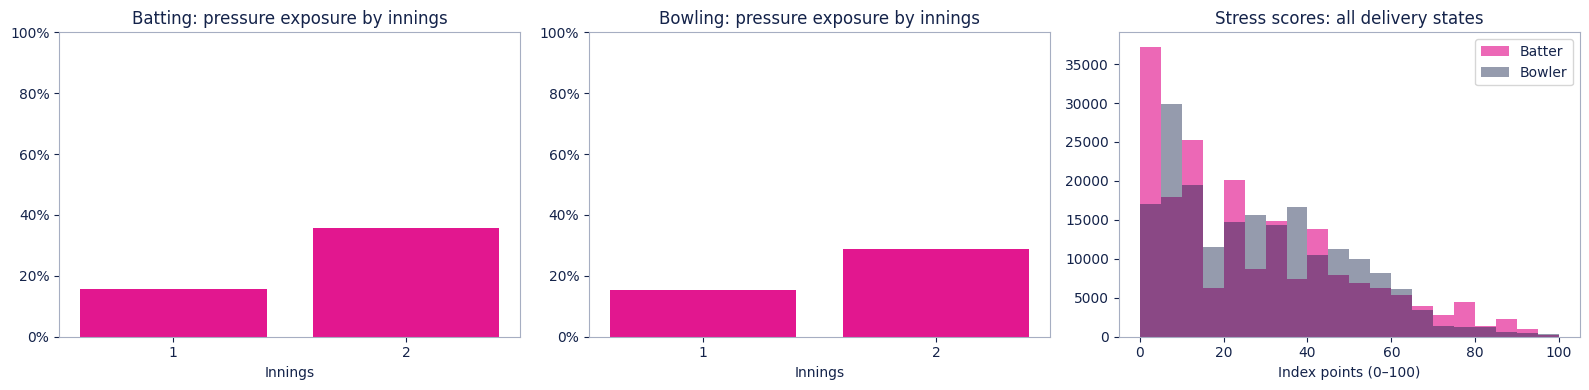

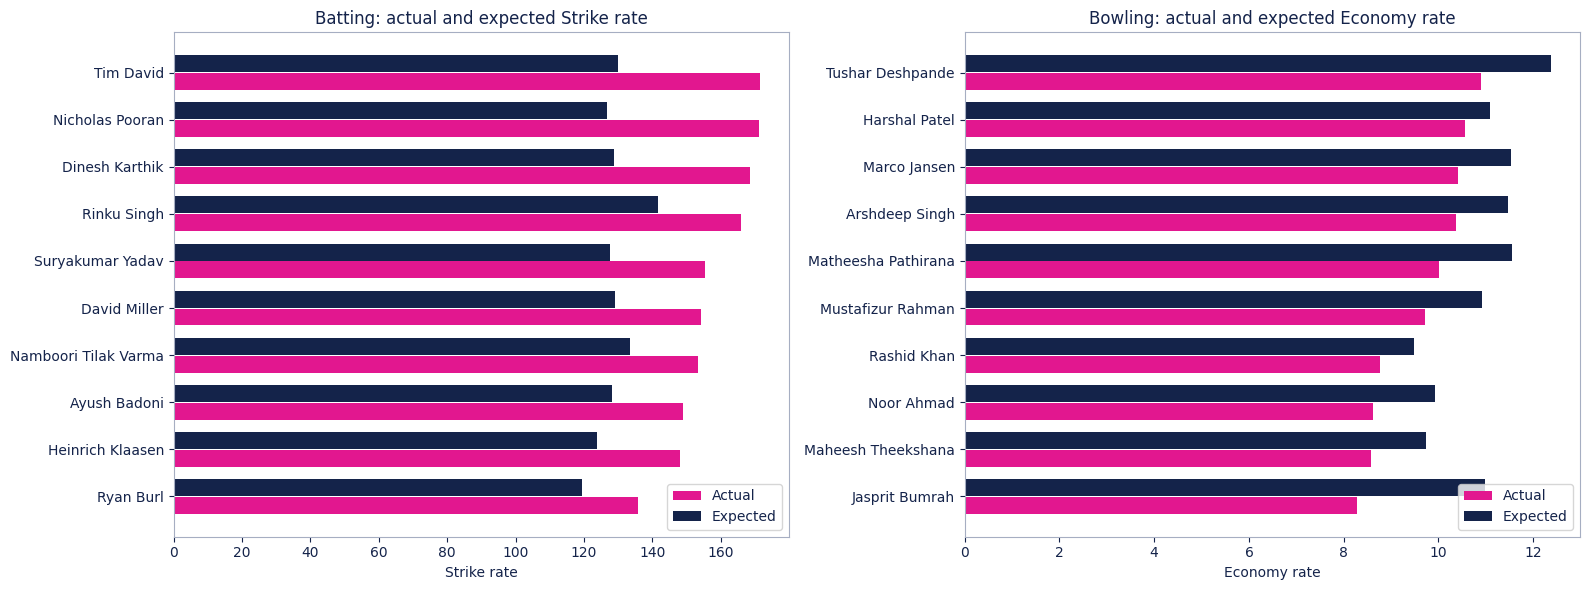

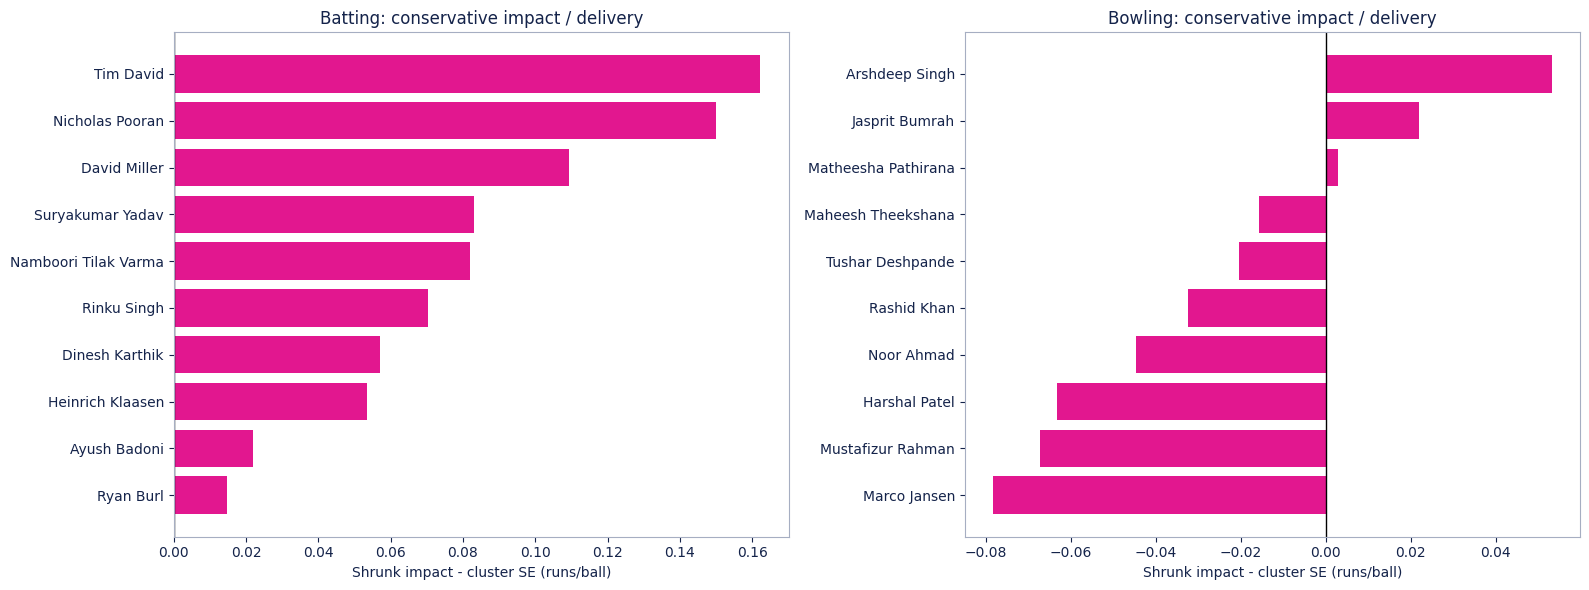

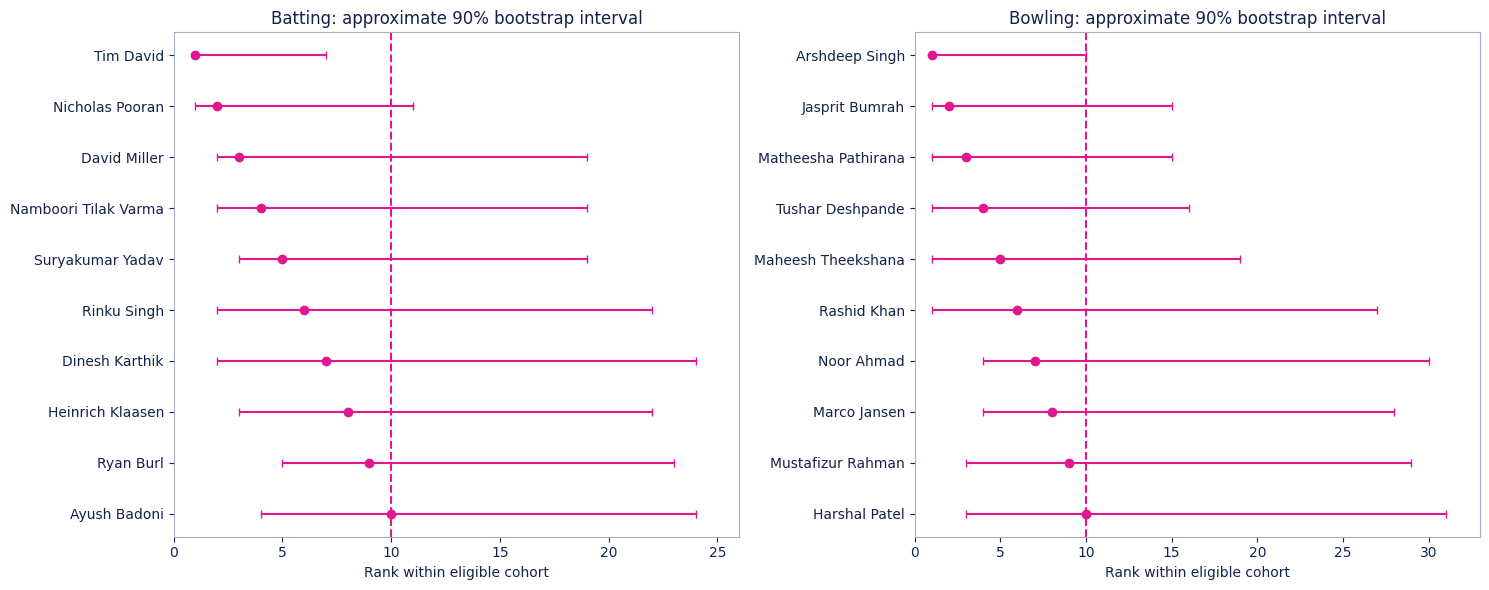

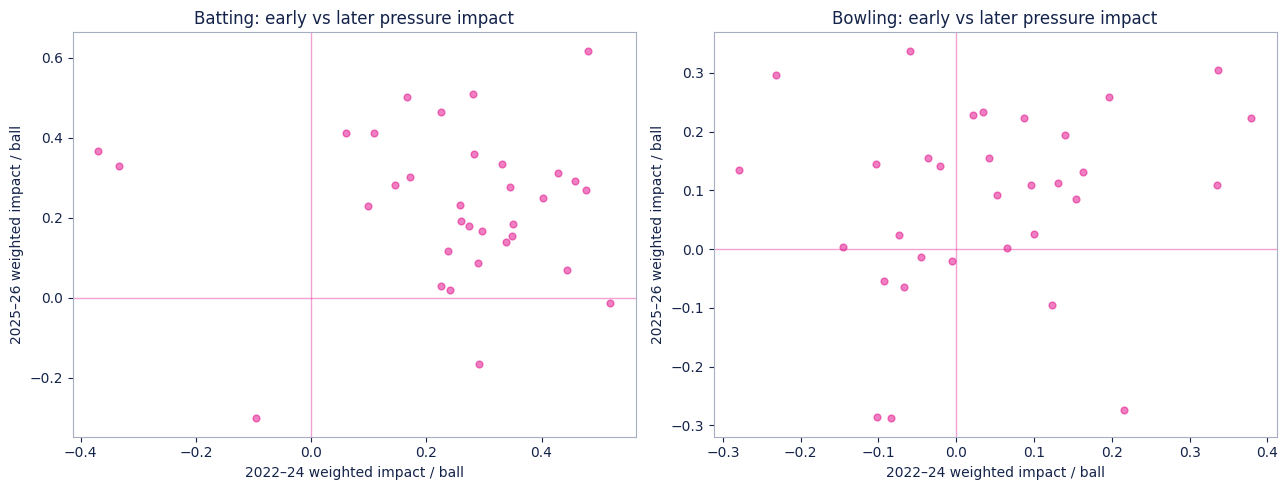

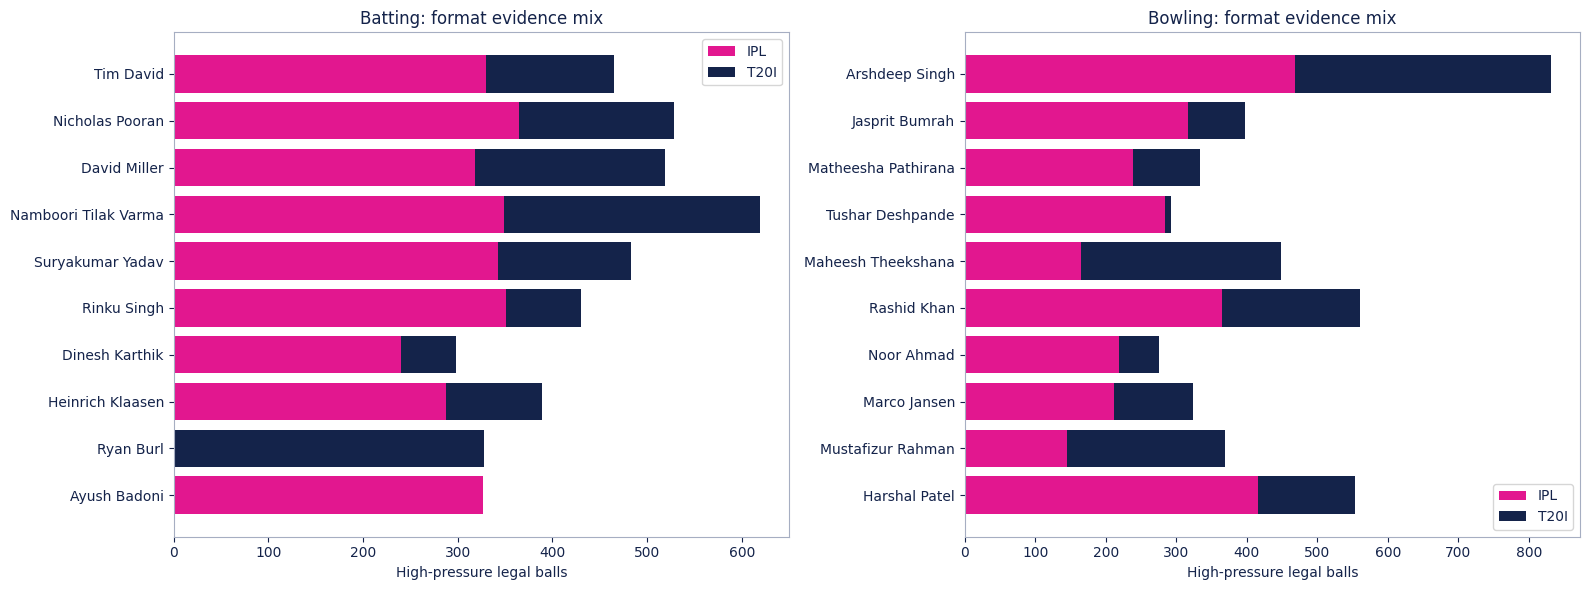

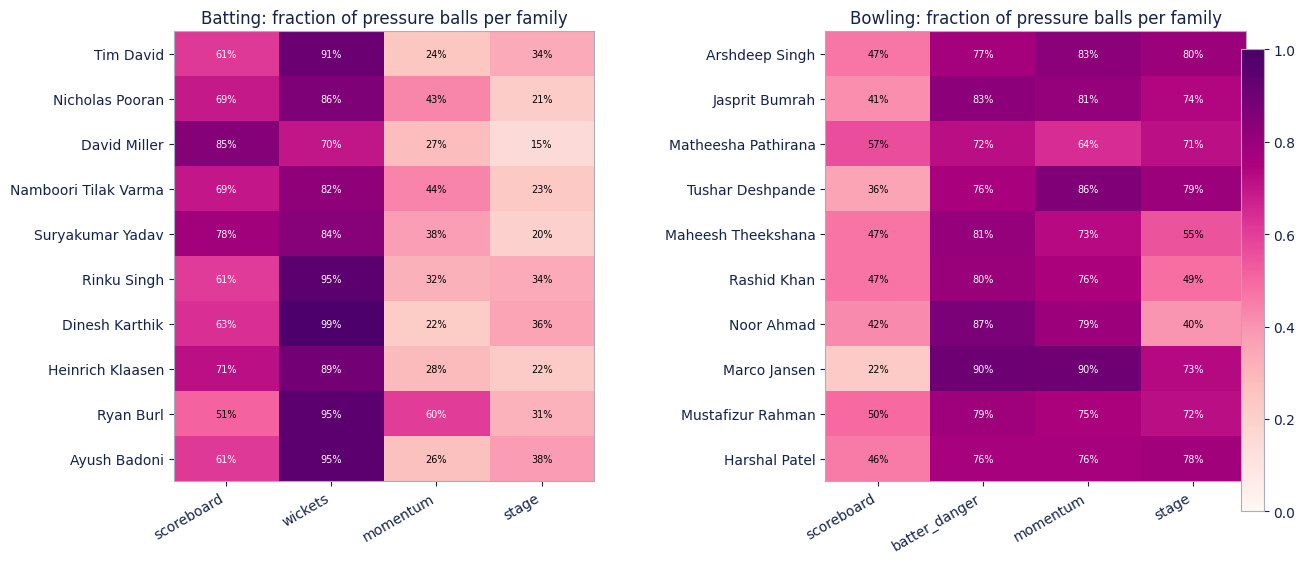

In [24]:
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'font.size':10,'font.family':'DejaVu Sans'})

fig,axs=plt.subplots(1,3,figsize=(16,4.0))
for j,(z,name) in enumerate([(d,'Batting'),(b,'Bowling')]):
    q=z.groupby('innings').pressure.mean()
    axs[j].bar(q.index.astype(str),q.values); axs[j].set_title(f'{name}: pressure exposure by innings');axs[j].set_xlabel('Innings');axs[j].set_ylim(0,1);axs[j].yaxis.set_major_formatter(PercentFormatter(1.0))
axs[2].hist(d.stress_score,bins=20,alpha=.65,label='Batter');axs[2].hist(b.stress_score,bins=20,alpha=.45,label='Bowler');axs[2].set_title('Stress scores: all delivery states');axs[2].set_xlabel('Index points (0–100)');axs[2].legend()
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_01_pressure_distribution.png'),dpi=170,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(1,2,figsize=(16,6))
for ax,t,name,unit in [(axs[0],play,'Batting','Strike rate'),(axs[1],bow_play,'Bowling','Economy rate')]:
    v=t.head(10).sort_values('actual_rate'); yy=np.arange(len(v))
    ax.barh(yy-.19,v.actual_rate,height=.36,label='Actual'); ax.barh(yy+.19,v.expected_rate,height=.36,label='Expected')
    ax.set_yticks(yy,v.name);ax.set_title(f'{name}: actual and expected {unit}');ax.set_xlabel(unit);ax.legend()
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_02_actual_vs_expected.png'),dpi=170,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(1,2,figsize=(16,6))
for ax,t,name in [(axs[0],play,'Batting'),(axs[1],bow_play,'Bowling')]:
    v=t.head(10).sort_values('impact_lcb');xx=v.impact_lcb
    ax.barh(v.name,xx);ax.axvline(0,lw=1,color='black');ax.set_title(f'{name}: conservative impact / delivery');ax.set_xlabel('Shrunk impact - cluster SE (runs/ball)')
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_03_conservative_impact.png'),dpi=170,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(1,2,figsize=(15,6))
for ax,t,name in [(axs[0],play,'Batting'),(axs[1],bow_play,'Bowling')]:
    v=t.head(10).sort_values('rank',ascending=False); yy=np.arange(len(v)); mid=v['rank'].to_numpy()
    ax.errorbar(mid,yy,xerr=[np.maximum(0,mid-v.rank_p05.to_numpy()),np.maximum(0,v.rank_p95.to_numpy()-mid)],fmt='o',capsize=3)
    ax.set_yticks(yy,v.name);ax.axvline(10,ls='--');ax.set_xlim(0,max(15,v.rank_p95.max()+2));ax.set_xlabel('Rank within eligible cohort');ax.set_title(f'{name}: approximate 90% bootstrap interval')
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_04_rank_uncertainty.png'),dpi=170,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,(role,q) in zip(axs,transfer_data.items()):
    if len(q):
        ax.scatter(q.early_impact,q.late_impact,alpha=.55,s=24)
        ax.axhline(0,lw=1,alpha=.4);ax.axvline(0,lw=1,alpha=.4)
    ax.set_title(f'{role.title()}: early vs later pressure impact');ax.set_xlabel('2022–24 weighted impact / ball');ax.set_ylabel('2025–26 weighted impact / ball')
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_05_temporal_transfer.png'),dpi=170,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(1,2,figsize=(16,6))
for ax,role,ranked in [(axs[0],'batting',play),(axs[1],'bowling',bow_play)]:
    z=context[(context.role==role)&(context.segment_type=='format')].pivot_table(index='name',columns='segment',values='pressure_legal_balls',aggfunc='sum').fillna(0)
    z=z.reindex(ranked.head(10).name[::-1]);y=np.arange(len(z))
    ax.barh(y,z.get('IPL',pd.Series(0,index=z.index)),label='IPL')
    ax.barh(y,z.get('T20I',pd.Series(0,index=z.index)),left=z.get('IPL',pd.Series(0,index=z.index)),label='T20I')
    ax.set_yticks(y,z.index);ax.set_xlabel('High-pressure legal balls');ax.set_title(f'{role.title()}: format evidence mix');ax.legend()
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_06_ipl_t20i_evidence_mix.png'),dpi=170,bbox_inches='tight');plt.show()
fig,axs=plt.subplots(1,2,figsize=(16,6))
for ax,role,ranked,families in [(axs[0],'batting',play,['scoreboard','wickets','momentum','stage']),
                                (axs[1],'bowling',bow_play,['scoreboard','batter_danger','momentum','stage'])]:
    z=context[(context.role==role)&(context.segment_type=='family')].pivot_table(index='name',columns='segment',values='pressure_legal_balls',aggfunc='sum').fillna(0)
    z=z.reindex(ranked.head(10).name);z=z.reindex(columns=families,fill_value=0)
    denominator=ranked.head(10).set_index('name').loc[z.index,'press_balls'].to_numpy()[:,None]
    q=z.to_numpy()/np.maximum(denominator,1)
    heat=ax.imshow(q,aspect='auto',vmin=0,vmax=1,cmap='RdPu')
    ax.set_xticks(np.arange(len(families)),families,rotation=30,ha='right');ax.set_yticks(np.arange(len(z)),z.index)
    ax.set_title(f'{role.title()}: fraction of pressure balls per family')
    for yy in range(len(z)):
      for xx in range(len(families)):ax.text(xx,yy,f'{q[yy,xx]:.0%}',ha='center',va='center',fontsize=7,color='white' if q[yy,xx]>.6 else 'black')
fig.colorbar(heat,ax=axs.tolist(),fraction=.03,pad=.06)
fig.subplots_adjust(left=.21,right=.88,bottom=.16,top=.91,wspace=.55)
fig.savefig(os.path.join(OUTPUT_DIR,'FIG_07_family_evidence_coverage.png'),dpi=170,bbox_inches='tight');plt.show()


<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 25 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Export individual pressure-signal coverage</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Record how often every defined pressure signal occurs and in how many matches. This supports the signal definitions in the methodology report.</div>
</div>

In [25]:
exposure=[]
for role,frame,signal_names in [('batting',d,scenarios),('bowling',b,BO_SCENARIOS)]:
    for name in signal_names:
        a=frame[frame[name].eq(1)]
        exposure.append(dict(role=role,signal=name,deliveries=len(a),matches=a.match_id.nunique(),
                             pressure_gate_share=float(a.pressure.mean()) if len(a) else 0))
pd.DataFrame(exposure).to_csv(os.path.join(OUTPUT_DIR,'pressure_signal_exposure.csv'),index=False)
import json
facts=dict(scope='2022-2026 IPL+T20I',matches=int(d.match_id.nunique()),deliveries=int(len(d)),
           batting_gate=round(float(BAT_GATE),3),bowling_gate=round(float(BO_GATE),3),
           batting_share=float(d.pressure.mean()),bowling_share=float(b.pressure.mean()),
           eligible_batters=len(play),eligible_bowlers=len(bow_play),
           batting_names=BAT_FINAL.name.tolist(),bowling_names=BOWL_FINAL.name.tolist(),
           config=CFG,transfer=transfer.to_dict(orient='records'),
           fit=fit.to_dict(orient='records'),
           pressure_signals={'batting':list(scenarios),'bowling':list(BO_SCENARIOS)})
with open(os.path.join(OUTPUT_DIR,'REPORT_FACTS.json'),'w') as f:json.dump(facts,f,indent=2)
print('Completed: precisely two player top-10 CSVs, five figure PNGs, transparent validation files and report facts.')


Completed: precisely two player top-10 CSVs, five figure PNGs, transparent validation files and report facts.


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">H. Temporal robustness figures</span>
</div>

The following figures summarize each selected player's top-10 stability under match-block resampling and complete-season removal, and the year-ordered predictive-error diagnostic.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 26 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Visualize temporal stability and validation</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Plot bootstrap selection frequencies, leave-one-season-out stability, and later-year error. These reveal which selections have stronger or weaker statistical support.</div>
</div>

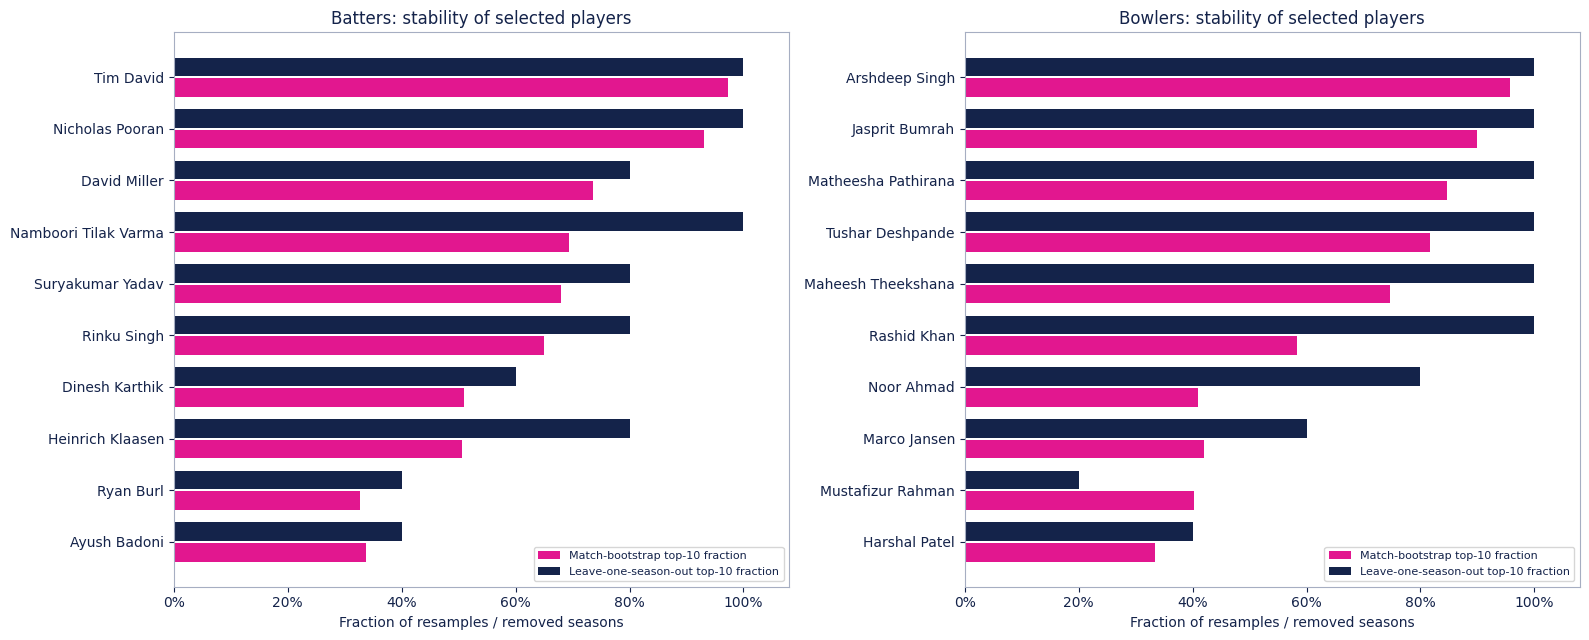

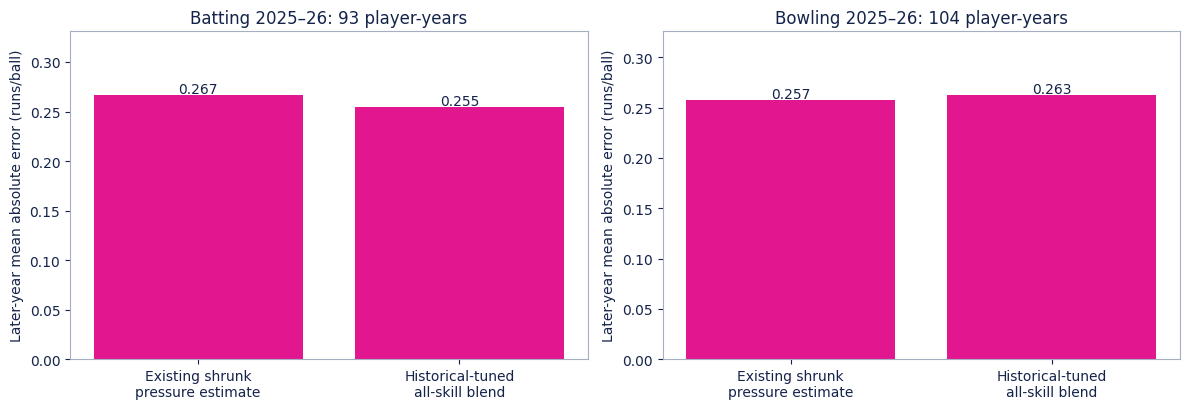

IPL + T20I results ready: two top-10 selection tables and supporting analysis figures.


In [26]:
from matplotlib.ticker import PercentFormatter

fig,axes=plt.subplots(1,2,figsize=(16,6.5))
for ax,ranking,role in [(axes[0],play,'Batters'),(axes[1],bow_play,'Bowlers')]:
    r=ranking.head(10).sort_values('rank',ascending=False)
    y=np.arange(len(r))
    ax.barh(y-.20,r.bootstrap_top10_share,height=.36,label='Match-bootstrap top-10 fraction')
    ax.barh(y+.20,r.season_removal_top10_share,height=.36,label='Leave-one-season-out top-10 fraction')
    ax.set_yticks(y,r.name);ax.set_xlim(0,1.08);ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f'{role}: stability of selected players');ax.set_xlabel('Fraction of resamples / removed seasons');ax.legend(fontsize=8,loc='lower right')
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_08_temporal_selection_resilience.png'),dpi=170,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for ax,(_,r) in zip(axes,walk_summary.iterrows()):
    vals=[r.baseline_MAE,r.candidate_MAE]
    ax.bar(['Existing shrunk\npressure estimate','Historical-tuned\nall-skill blend'],vals)
    ax.set_title(f"{r['role'].title()} 2025–26: {int(r['evaluation_player_years'])} player-years")
    ax.set_ylabel('Later-year mean absolute error (runs/ball)')
    ax.set_ylim(0,max(vals)*1.24)
    for j,v in enumerate(vals):ax.text(j,v+.002,f'{v:.3f}',ha='center',fontsize=10)
fig.tight_layout();fig.savefig(os.path.join(OUTPUT_DIR,'FIG_09_walkforward_error.png'),dpi=170,bbox_inches='tight');plt.show()

bat_audit=play.head(10).reset_index()[['rank','striker_id','name','bootstrap_top10_share',
  'season_removal_top10_share','season_removal_worst_rank','supported_seasons','evidence_tier']]
bowl_audit=bow_play.head(10).reset_index()[['rank','bowler_id','name','bootstrap_top10_share',
  'season_removal_top10_share','season_removal_worst_rank','supported_seasons','evidence_tier']]
pd.concat([bat_audit.assign(role='batting'),bowl_audit.rename(columns={'bowler_id':'striker_id'}).assign(role='bowling')],ignore_index=True).rename(columns={'striker_id':'player_id'}).to_csv(
  os.path.join(OUTPUT_DIR,'selected_player_reliability_evidence.csv'),index=False)
assert len(BAT_FINAL)==10 and len(BOWL_FINAL)==10
assert BAT_FINAL['striker_id'].is_unique and BOWL_FINAL['bowler_id'].is_unique
assert np.array_equal(BAT_FINAL['striker_id'].to_numpy(),play.head(10).index.to_numpy())
assert np.array_equal(BOWL_FINAL['bowler_id'].to_numpy(),bow_play.head(10).index.to_numpy())
assert set(BAT_FINAL.evidence_tier.unique()).issubset({'Well-supported within model','Moderate within model','Uncertain / borderline'})
with open(os.path.join(OUTPUT_DIR,'REPORT_FACTS.json')) as _fp:_facts=json.load(_fp)
_facts['analysis_scope']='Combined IPL and T20I pressure assessment'
_facts['reliability_settings']=RELIABILITY_CFG
_facts['chronological_reliability']=walk_summary.to_dict(orient='records')
_facts['interpretation']='No claim of unique correctness, future predictive rank validity, or causal mental pressure.'

with open(os.path.join(OUTPUT_DIR,'REPORT_FACTS.json'),'w') as _fp:json.dump(_facts,_fp,indent=2)
print('IPL + T20I results ready: two top-10 selection tables and supporting analysis figures.')


<div style="background:#14234A; border-left:8px solid #E2178F; border-radius:8px; padding:16px 20px; margin:28px 0 12px;">
  <span style="font-family:Arial,Helvetica,sans-serif;color:#FFFFFF;font-size:20px;font-weight:700;line-height:1.4;">I. Bowling multi-season and innings-phase evidence</span>
</div>

**Bowling eligibility:** at least 750 career legal balls, 250 high-pressure legal balls, 30 pressure matches, 18 meaningful pressure matches, 240 ordinary legal balls, and at least three independent seasons each containing 35 pressure legal balls across four matches. These conditions are applied identically to every bowler; no player is added by name.

**Innings-phase breadth:** the 4%-weighted bowling breadth metric uses normalized Shannon entropy of pressure-delivery exposure across powerplay, middle and death phases. The metric measures exposure diversity, not superior bowling quality by itself. The remaining signals, fixed scoring equation, match-bootstrap uncertainty, and year-ordered diagnostics are included in the analysis.

<div style="border:1px solid #F2C4DC;border-left:5px solid #E2178F; background:#FFF3F9; border-radius:9px; padding:13px 17px; margin:19px 0 7px; font-family:Arial,Helvetica,sans-serif;">
  <div style="color:#E2178F; font-size:10px; font-weight:800; letter-spacing:2px; margin-bottom:3px;">STEP 27 &nbsp; | &nbsp; ANALYSIS NOTE</div>
  <div style="color:#14234A; font-size:16px; font-weight:700; line-height:1.3; margin-bottom:5px;">Audit bowling across seasons and phases</div>
  <div style="color:#52617B; font-size:13px; line-height:1.6;">Verify that selected bowlers meet the multi-season conditions, then visualize their season-by-season impact and powerplay/middle/death pressure exposure.</div>
</div>

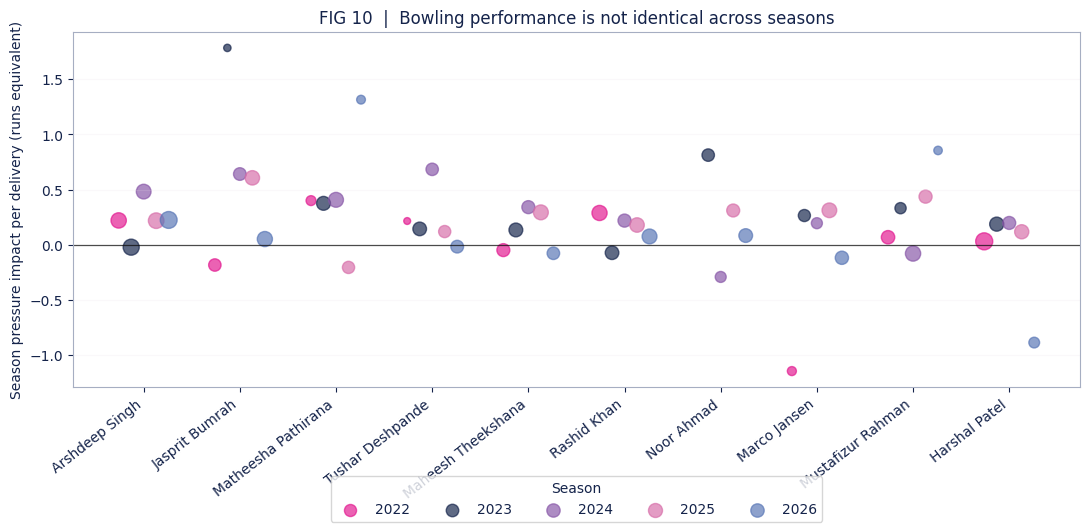

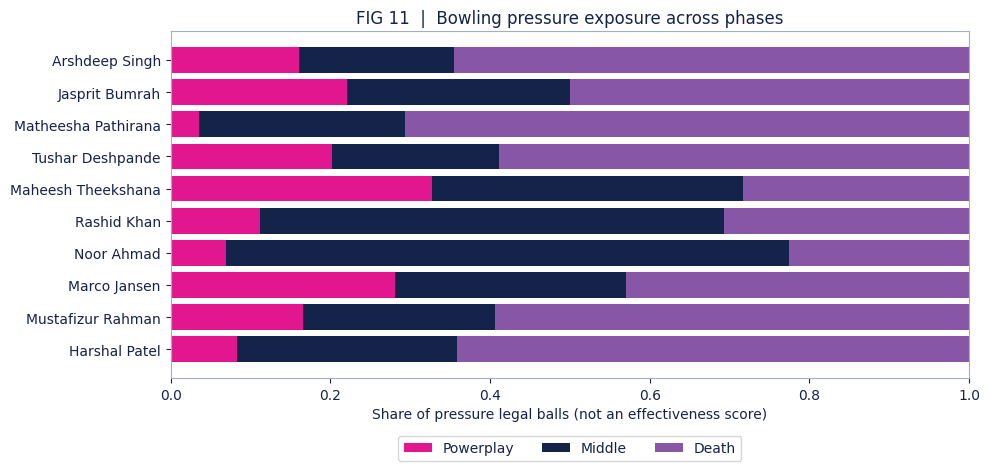

Final bowler evidence:                name  rank  qualifying_seasons  pressure_seasons  press_balls  press_matches  meaningful_matches  impact_raw  impact_lcb  phase_powerplay_share  phase_middle_share  phase_death_share  breadth  bootstrap_top10_share  season_removal_top10_share
     Arshdeep Singh     1                   5                 5          831            122                71.0       0.224       0.053                  0.161               0.194              0.645    0.815                  0.957                         1.0
     Jasprit Bumrah     2                   4                 5          398             61                30.0       0.316       0.022                  0.221               0.279              0.500    0.943                  0.900                         1.0
Matheesha Pathirana     3                   3                 5          334             41                27.0       0.306       0.003                  0.036               0.257              0.707    0.

In [27]:
assert CFG['MIN_BOWL_SUPPORTED_SEASONS']==3
assert bow_play.qualifying_seasons.ge(3).all()
assert np.isfinite(bow_play[['rating','breadth','impact_lcb']].to_numpy()).all()
assert len(BOWL_FINAL)==10
assert BOWL_FINAL['bowler_id'].isin(bow_play.index).all()
assert np.array_equal(BAT_FINAL.striker_id.to_numpy(), play.head(10).index.to_numpy())
assert (bow_play.breadth.between(0,1)).all()
assert bow_play.breadth.nunique()>3, 'Phase entropy must distinguish eligible bowlers'

bow_audit=bow_play.head(10)[['name','rank','qualifying_seasons','pressure_seasons','press_balls',
                    'press_matches','meaningful_matches','impact_raw','impact_lcb',
                    'phase_powerplay_share','phase_middle_share','phase_death_share','breadth',
                    'bootstrap_top10_share','season_removal_top10_share']].copy()
bow_audit.to_csv(os.path.join(OUTPUT_DIR,'bowling_multiseason_and_phase_evidence.csv'),index=True)

aux=bp.loc[bp.legal.eq(1)].copy()
aux['audit_year']=aux.match_date_dt.dt.year
aux['w_imp']=aux.ball_impact*aux.pressure_weight
annual_bowler=aux.groupby(['bowler_id','audit_year']).agg(
    legal_pressure=('legal','sum'),n_matches=('match_id','nunique'),
    weighted_impact=('w_imp','sum'),pressure_w=('pressure_weight','sum')).reset_index()
annual_bowler['run_equivalent_impact_per_ball']=annual_bowler.weighted_impact/annual_bowler.pressure_w.clip(lower=.01)
annual_bowler['qualifies_as_supported_season']=(annual_bowler.legal_pressure>=CFG['MIN_BOWL_YEAR_PRESS_BALLS']) & (annual_bowler.n_matches>=CFG['MIN_BOWL_YEAR_PRESS_MATCHES'])
annual_bowler.to_csv(os.path.join(OUTPUT_DIR,'bowling_annual_pressure_evidence.csv'),index=False)

sel=BOWL_FINAL[['bowler_id','rank','name']].merge(annual_bowler,on='bowler_id',how='left')
fig,ax=plt.subplots(figsize=(11,5.6))
x=np.arange(10)
for y,g in sel.groupby('audit_year'):
    offset=(int(y)-2024)*.13
    ids=g.set_index('rank')
    yy=ids.run_equivalent_impact_per_ball.reindex(np.arange(1,11))
    ax.scatter(x+offset, yy, s=np.sqrt(ids.legal_pressure.reindex(np.arange(1,11)).fillna(0).to_numpy())*10,
                label=str(int(y)),alpha=.68)
ax.axhline(0,color='black',lw=.9,alpha=.7)
ax.set_xticks(x, BOWL_FINAL['name'],rotation=38,ha='right')
ax.set_ylabel('Season pressure impact per delivery (runs equivalent)')
ax.set_title('FIG 10  |  Bowling performance is not identical across seasons')
ax.grid(axis='y',alpha=.18)
ax.legend(title='Season',ncol=5,loc='upper center',bbox_to_anchor=(.5,-.23))
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR,'FIG_10_bowling_multiseason_variation.png'),dpi=155,bbox_inches='tight')
plt.show()

ax=bow_play.head(10)[['phase_powerplay_share','phase_middle_share','phase_death_share']].rename(columns={
    'phase_powerplay_share':'Powerplay','phase_middle_share':'Middle','phase_death_share':'Death'})
fig,axs=plt.subplots(figsize=(10,4.9))
left=np.zeros(len(ax))
for name in ax:
    axs.barh(np.arange(len(ax)),ax[name].to_numpy(),left=left,label=name)
    left+=ax[name].to_numpy()
axs.set_yticks(np.arange(len(ax)),bow_play.head(10)['name'])
axs.invert_yaxis();axs.set_xlim(0,1);axs.set_xlabel('Share of pressure legal balls (not an effectiveness score)')
axs.set_title('FIG 11  |  Bowling pressure exposure across phases')
axs.legend(loc='lower center',bbox_to_anchor=(.5,-.26),ncol=3)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR,'FIG_11_bowling_phase_coverage.png'),dpi=155,bbox_inches='tight')
plt.show()
print('Final bowler evidence:',bow_audit.head(10).round(3).to_string(index=False))
print('Sunil Narine remains eligible:',(bow_play.name=='Sunil Narine').any())
